# 05 – Bee Haven: Analyse (N5)

> **Seit 30.09.2026 N5** (vorher N4). Läuft **bei Bedarf**, nicht in der täglichen Pipeline. Die Gold-Tabellen (Stunden, Tageswerte) erzeugt jetzt **N4 Gold**; diese Analyse rechnet für die Tageszeit-Auswertungen mit den Minutenwerten aus Silver (genauer als Stundenwerte).

**Ziel:** Auswertung der bereinigten Sensordaten eines Standorts (`STADT`) als Grundlage für Dashboard, Folgeanalysen und Handlungsempfehlungen. Grafiken werden in `04_images/<stadt>/` gespeichert.

**Fragen:**

- **F1:** Wie entwickelt sich das Gewicht des Bienenstocks über das Jahr (Honigertrag, Winterzehrung)?
- **F2:** Wann sind die Bienen am aktivsten (Ausflug/Einflug je Tag und Monat)?
- **F3:** Hängt die Flugaktivität mit der Temperatur zusammen?

**Datenbasis:** neueste Version in `silver/cleaned/<stadt>/<sensor>/` (Parameter `STADT`); nur Werte mit Qualität „ok…“ (ungültige und fehlende Werte fließen nicht ein).

**Weitere Auswertungen (Pflichtenheft PH-ITS-002, Kap. 2.3/2.4):** A2 Tag/Dämmerung/Nacht · A3 Außentemperatur in 5-Grad-Stufen · A4 Stunde × Monat · A5 Mittagshitze 12–15 Uhr · A6 Regen/Sonne · A7–A10 Feuchte, Strahlung, Wind, Luftdruck · H1 Honigproduktion

**Ergebnistexte:** erklären, wie man jedes Ergebnis liest, und gelten für jeden Standort; die Zahlen stehen in der Ausgabe. Die Tabellen „Kernaussagen je Stadt“ fassen die Ergebnisse der beiden Standorte zusammen (Stand 02.10.2026). Standortvergleich der Honigproduktion: `06_vergleich_standorte.ipynb`.

## 0. Bibliotheken und Pfade

**Kontrollwert:** keine Ausgabe, keine Fehlermeldung

In [1]:
# --- Parameter: Standort (neue Stadt = Zeile in lakehouse/konfiguration/standorte.csv + Ordner in silver/processing) ---
STADT = "schwartau"                                       # Standort = Unterordner in bronze/silver/gold und Teil der Dateinamen

# --- Bibliotheken laden ---
import numpy as np                       # numpy: Rechnen mit Zahlenreihen, Fallunterscheidungen
import pandas as pd                      # pandas: Tabellen auswerten
import matplotlib.pyplot as plt          # matplotlib: Diagramme zeichnen
from pathlib import Path                 # Path: Ordner- und Dateipfade

# --- Pfade festlegen ---
PROJEKT = Path.cwd().parent                                                        # Projektordner
CLEANED = PROJEKT / "02_daten_ITS-Data" / "lakehouse" / "silver" / "cleaned" / STADT  # Eingang: bereinigte Daten
GOLD = PROJEKT / "02_daten_ITS-Data" / "lakehouse" / "gold" / STADT                         # Ausgang: Tageskennzahlen
BILDER = PROJEKT / "04_images" / STADT                                                # Diagramme je Stadt (04_images/<stadt>/)
BILDER.mkdir(parents=True, exist_ok=True)                                             # Ordner anlegen, falls neu
sensoren = ["flow", "humidity", "temperature", "weight"]                           # Liste der Sensoren

# --- Standortdaten aus der Konfiguration (Koordinaten, Zeitzone) ---
standorte = pd.read_csv(PROJEKT / "02_daten_ITS-Data" / "lakehouse" / "konfiguration" / "standorte.csv", index_col="stadt")
if STADT not in standorte.index:                          # unbekannte Stadt -> sofort abbrechen statt mit falschen Daten weiterrechnen
    raise ValueError(f"Standort '{STADT}' fehlt in konfiguration/standorte.csv – Zeile mit Koordinaten und Zeitzone ergänzen")
ORT = standorte.loc[STADT]                                # eine Zeile: name, breite, laenge, zeitzone, quelle

# --- Sensor-Regeln je Standort (Einheit der Rohdaten, gültiger Bereich) und bekannte Ausfallzeiträume ---
KONFIG = PROJEKT / "02_daten_ITS-Data" / "lakehouse" / "konfiguration"                  # Ordner mit den Konfigurationstabellen
sensoren_cfg = pd.read_csv(KONFIG / "sensoren.csv")                                    # eine Zeile je Stadt und Sensor
REGELN = sensoren_cfg[sensoren_cfg["stadt"] == STADT].set_index("sensor")              # Regeln dieser Stadt: einheit_roh, min, max
ausschluesse = pd.read_csv(KONFIG / "ausschluesse.csv")                                # bekannte Ausfallzeiträume (z. B. Stock nicht auf Waage)
AUSSCHLUESSE = ausschluesse[ausschluesse["stadt"] == STADT].copy()                     # nur Zeiträume dieser Stadt
AUSSCHLUESSE[["von_utc", "bis_utc"]] = AUSSCHLUESSE[["von_utc", "bis_utc"]].apply(pd.to_datetime, utc=True)  # Text -> UTC-Zeit
ZEITZONE = ORT["zeitzone"]                                # Ortszeit der Rohdaten (Deutschland: Europe/Berlin)

**Ergebnis:**

Bibliotheken und Pfade ohne Fehler geladen.

## 1. Neueste bereinigte Version einlesen

**Warum „neueste“?** In `cleaned` liegt jede Bereinigung als eigene Version mit Zeitstempel. Wir nehmen die jüngste; ältere bleiben für den Rückgriff erhalten.

**Kontrollwert (Ergebnis N2, muss übereinstimmen):** je Sensor genau eine Datei gefunden; Zeilen wie in N2 Kapitel 7

In [2]:
# --- Je Sensor die neueste Datei in cleaned finden und einlesen ---
daten = {}                                                              # leeres Dictionary: Sensor -> Tabelle
for s in sensoren:                                                      # für jeden Sensor ...
    dateien = sorted((CLEANED / s).glob(f"{s}_{STADT}_cleaned__*.csv"))  # ... alle Versionen suchen (Name enthält Zeitstempel)
    neueste = dateien[-1]                                               # ... letzte nach Namen = neueste Version
    daten[s] = pd.read_csv(neueste)                                     # ... einlesen
    daten[s]["zeit_utc"] = pd.to_datetime(daten[s]["zeit_utc"], utc=True)  # ... CSV liefert Text -> wieder in UTC-Zeit umwandeln
    print(f"{s:12} {len(daten[s]):>10,} Zeilen  aus {neueste.name}  ({len(dateien)} Version(en) vorhanden)")  # ... Kontrolle

flow          1,256,918 Zeilen  aus flow_schwartau_cleaned__2026-10-01_151930_UTC.csv  (1 Version(en) vorhanden)
humidity          1,761 Zeilen  aus humidity_schwartau_cleaned__2026-10-01_151930_UTC.csv  (1 Version(en) vorhanden)


temperature     253,430 Zeilen  aus temperature_schwartau_cleaned__2026-10-01_151930_UTC.csv  (1 Version(en) vorhanden)
weight            1,761 Zeilen  aus weight_schwartau_cleaned__2026-10-01_151930_UTC.csv  (1 Version(en) vorhanden)


**Ergebnis:** Je Sensor die neueste Version aus `silver/cleaned/<stadt>/` geladen (ältere Versionen liegen im `_archiv` des jeweiligen Sensorordners); Zeilen in der Ausgabe.

| Kontrollwerte | flow · humidity · temperature · weight (Zeilen) |
| :-- | :-- |
| Schwartau | 1.256.918 · 1.761 · 253.430 · 1.761 |
| Würzburg | 1.027.761 · 20.845 · 958.831 · 1.035.861 |

## 2. Nur gültige Werte verwenden

**Regel:** Für die Analyse zählen nur Zeilen, deren Qualität mit „ok“ beginnt (also auch „ok: Frost (plausibel)“).

**Warum?** Ungültige Werte wurden in N2 geleert; fehlende Werte werden nicht erfunden (R3).

**Kontrollwert:** gültige Zeilen wie in N4 Kapitel 2

In [3]:
# --- Nur Zeilen mit Qualität "ok..." behalten ---
gueltig = {}                                                            # leeres Dictionary für die gültigen Daten
for s in sensoren:                                                      # für jeden Sensor ...
    maske = daten[s]["qualitaet"].str.startswith("ok")                  # ... True, wenn die Qualität mit "ok" beginnt
    gueltig[s] = daten[s][maske]                                        # ... nur diese Zeilen übernehmen
    print(f"{s:12} {len(gueltig[s]):>10,} gültige Zeilen")              # ... Kontrolle

flow          1,256,918 gültige Zeilen
humidity          1,718 gültige Zeilen
temperature     251,398 gültige Zeilen
weight            1,619 gültige Zeilen


**Ergebnis:** gültige Zeilen je Sensor (Ausgabe).

| Kontrollwerte | gültig: flow · humidity · temperature · weight |
| :-- | :-- |
| Schwartau | 1.256.918 · 1.718 · 251.398 · 1.619 |
| Würzburg | 1.027.761 · 17.263 · 794.250 · 1.015.006 |

## 3. Tageswerte bilden (für F1–F3; gespeichert werden sie in N4 Gold)

**Was passiert?** Die Messwerte werden je **Kalendertag (UTC)** zusammengefasst – das sind die Kennzahlen, die später in Gold und im Dashboard stehen:

- Gewicht: Tagesmittel in kg
- Flugaktivität: Summe Ausflug und Einflug je Tag (Ausflug ist negativ gemessen → als positive Anzahl) sowie **Flugbewegungen** = beide zusammen; auffällige Werte (R9, z. B. Fehlercode 7.999) werden nicht mitgezählt
- Temperatur: Tagesmittel, -minimum, -maximum
- Luftfeuchte: Tagesmittel

**Kontrollwert:** Anzahl Tage wie in N4 (Schwartau 881, Würzburg 870)

**Erwartung laut Recherche:** Temperatur im Stock im Sommer ca. 33–36 °C (Brutnest), im Winter deutlich niedriger (Wintertraube, Quellen T1–T3 in N2) – das Maximum sollte also um 35–37 °C liegen. **Eigene Erwartung:** Gewicht mit Beute ca. 30–90 kg (Pflichtenheft R5).

In [4]:
# --- Tageswerte je Sensor berechnen ---
tag = lambda t: t.set_index("zeit_utc").resample("D")                   # Hilfsfunktion: Daten nach Kalendertag (UTC) gruppieren
gewicht = tag(gueltig["weight"])["weight"].mean() / 1000                # Tagesmittel Gewicht, Gramm -> kg
fl_ok = gueltig["flow"].assign(                                         # flow ohne auffällige Werte (R9):
    flow_aus=gueltig["flow"]["flow_aus"].where(~gueltig["flow"]["flow_aus_auffaellig"]),  #   auffällige Ausflugwerte leeren
    flow_ein=gueltig["flow"]["flow_ein"].where(~gueltig["flow"]["flow_ein_auffaellig"]))  #   auffällige Einflugwerte leeren
ausflug = -tag(fl_ok)["flow_aus"].sum()                                 # Ausflüge je Tag (negativ gemessen -> positiv)
einflug = tag(fl_ok)["flow_ein"].sum()                                  # Einflüge je Tag
temp = tag(gueltig["temperature"])["temperature"].agg(["mean", "min", "max"])  # Temperatur: Mittel, Min, Max je Tag
feuchte = tag(gueltig["humidity"])["humidity"].mean()                   # Tagesmittel Luftfeuchte

tageswerte = pd.DataFrame({                                             # alles in EINE Tabelle zusammenführen:
    "gewicht_kg": gewicht,                                              #   Gewicht
    "ausflug": ausflug, "einflug": einflug,                             #   Flugaktivität
    "flugbewegungen": ausflug + einflug,                                #   Ein- + Ausflüge (unabhängig vom Vorzeichen-Thema)
    "temp_mittel": temp["mean"], "temp_min": temp["min"], "temp_max": temp["max"],  # Temperatur
    "feuchte_mittel": feuchte,                                          #   Luftfeuchte
}).round(2)                                                             # auf 2 Nachkommastellen runden
print(len(tageswerte), "Tage von", tageswerte.index.min().date(), "bis", tageswerte.index.max().date())  # Kontrolle
tageswerte.describe().round(1)                                          # Überblick: Min, Max, Mittelwert je Kennzahl

881 Tage von 2017-01-01 bis 2019-05-31


,gewicht_kg,ausflug,einflug,flugbewegungen,temp_mittel,temp_min,temp_max,feuchte_mittel
count,812.0,881.0,881.0,881.0,876.0,876.0,876.0,863.0
mean,60.6,30108.8,33436.5,63545.2,22.6,21.0,24.6,87.0
std,10.6,43143.2,51149.0,93957.2,11.6,12.0,11.1,12.6
min,46.6,-0.0,0.0,0.0,-5.5,-7.3,-3.7,30.9
25%,50.5,27.0,2.0,33.0,12.4,9.8,17.0,79.7
50%,60.0,4694.0,4903.0,9523.0,24.4,21.5,28.0,91.0
75%,67.7,52175.0,51281.0,104453.0,34.2,33.6,34.8,96.5
max,91.2,182808.0,233717.0,416525.0,35.4,35.1,37.5,100.0


**Ergebnis:** Tageswerte mit Zeitraum und Kennzahlen (Ausgabe). Flugbewegungen je Tag sind stark saisonal; die Tabelle `tageswerte` entspricht der Gold-Tabelle aus N4.

| Kernaussagen je Stadt | Tage · Gewicht im Mittel |
| :-- | :-- |
| Schwartau | 881 · ca. 60 kg; Median Flugbewegungen an Flugtagen ca. 14.600 |
| Würzburg | 870 · ca. 55 kg (Median 53,7 kg) |

## 4. F1 – Gewichtsverlauf über das Jahr

**Frage:** Wie entwickelt sich das Gewicht des Bienenstocks (Honigeintrag, Honigernte, Futterverbrauch im Winter)?

**Eigene Erwartung:** Zunahme im Frühjahr/Sommer, steile Abfälle im Sommer = Honigernte, langsame Abnahme im Winter

**Erwartung laut Recherche:** In der Tracht kann ein Stock an Spitzentagen 4–10 kg zunehmen (Nektar, noch nicht zu Honig eingedickt) [R1]; im Winter verbraucht ein Volk einige hundert Gramm pro Monat (Januar) bis mehrere Kilogramm (um März) [R2].

**Hinweis:** Zeiträume aus `ausschluesse.csv` (z. B. Schwartau 28.04.–02.07.2018, Befund E5: Stock nicht auf der Waage) sind in N2 als ungültig markiert und in der Grafik grau hinterlegt.

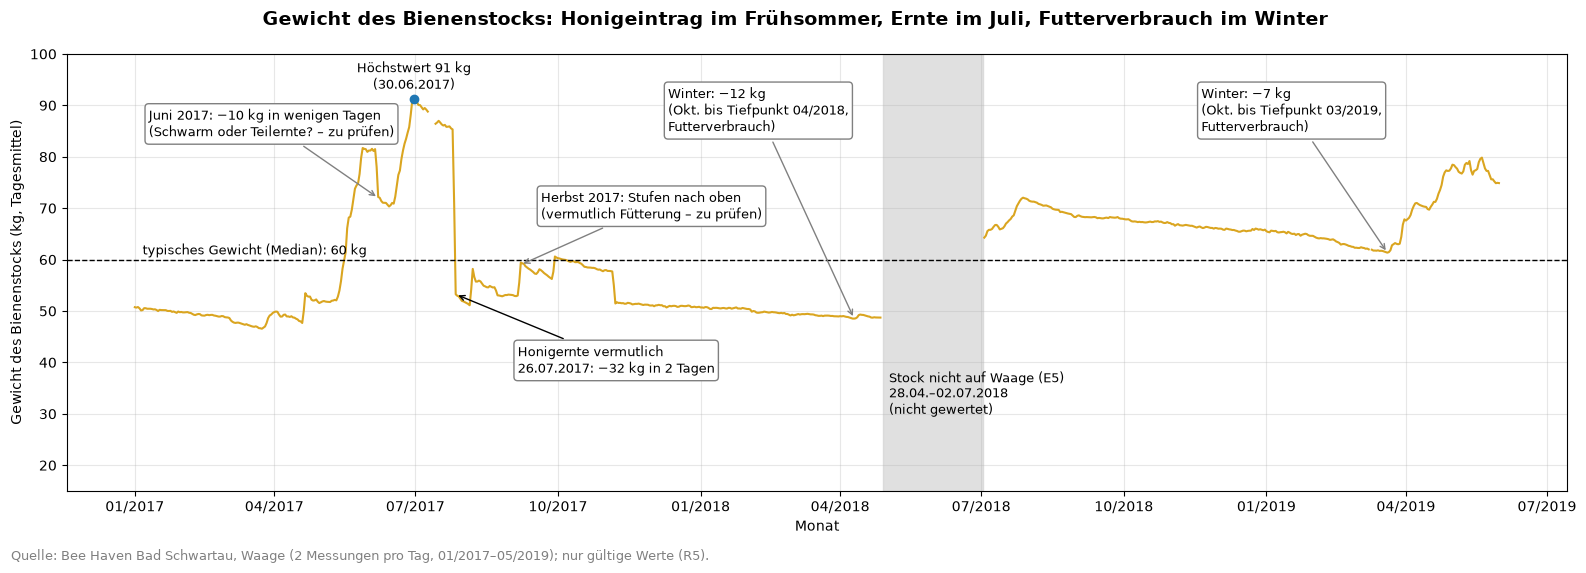

Median 60.0 kg · Höchstwert 91.2 kg am 30.06.2017 · größter Verlust 32.1 kg bis 27.07.2017


In [5]:
# --- F1: Gewichtsverlauf mit Kennzahlen und Ereignissen ---
import matplotlib.dates as mdates                                       # Datumsformat der x-Achse
g = tageswerte["gewicht_kg"].copy()                                     # Tagesmittel Gewicht (kg)
stoerungen = AUSSCHLUESSE[AUSSCHLUESSE["sensor"] == "weight"]            # bekannte Ausfallzeiträume dieser Stadt (konfiguration/ausschluesse.csv)
g_ok = g.copy()
for _, a in stoerungen.iterrows():                                      # Störzeiträume nicht als Gewicht werten
    g_ok = g_ok.where(~g_ok.index.to_series().between(a["von_utc"].floor("D"), a["bis_utc"].ceil("D")))
normal = g_ok.median()                                                  # Referenz: typisches Gewicht
ernte = g_ok.diff().nsmallest(1).index[0]                               # größter Tagesverlust = vermutlich Honigernte
verlust = g_ok.get(ernte - pd.Timedelta(days=2), g_ok[ernte]) - g_ok[ernte]   # Verlust über 2 Tage (kg); am Datenbeginn 0

fig, ax = plt.subplots(figsize=(16, 5.5))
fig.suptitle("Gewicht des Bienenstocks: Honigeintrag im Frühsommer, Ernte im Juli, Futterverbrauch im Winter",
             fontsize=14, fontweight="bold")
ax.plot(g_ok.index, g_ok, color="goldenrod", lw=1.5, label="Gewicht (Tagesmittel)")
ax.axhline(normal, color="black", ls="--", lw=1)
ax.text(g_ok.index[5], normal + 1, f"typisches Gewicht (Median): {normal:.0f} kg", fontsize=9)
for _, a in stoerungen.iterrows():                                      # Störzeiträume grau hinterlegen und beschriften
    ax.axvspan(a["von_utc"], a["bis_utc"], color="lightgrey", alpha=0.7)
    ax.text(a["von_utc"] + pd.Timedelta(days=4), 30, f"{a['grund']}\n{a['von_utc']:%d.%m.}–{a['bis_utc']:%d.%m.%Y}\n(nicht gewertet)", fontsize=9)
ax.annotate(f"Honigernte vermutlich\n{(ernte - pd.Timedelta(days=1)):%d.%m.%Y}: −{verlust:.0f} kg in 2 Tagen",
            xy=(ernte, g_ok[ernte]), xytext=(ernte + pd.Timedelta(days=40), 38), fontsize=9,
            arrowprops=dict(arrowstyle="->"), bbox=dict(boxstyle="round", fc="white", ec="grey"))
for von, bis in [("2017-10-01", "2018-04-27"), ("2018-10-01", "2019-03-31")]:   # Winter: Anfang Oktober → Tiefpunkt
    winter = g_ok[von:bis].dropna()
    if winter.empty:                                                      # keine Daten in diesem Winter (z. B. Datenlücke)
        continue
    tief = winter.idxmin()                                                # Tiefpunkt vor dem Frühjahrsanstieg
    ax.annotate(f"Winter: −{winter.iloc[0] - winter.min():.0f} kg\n(Okt. bis Tiefpunkt {tief:%m/%Y},\nFutterverbrauch)",
                xy=(tief, winter.min()), xytext=(tief - pd.Timedelta(days=120), 85), fontsize=9,
                arrowprops=dict(arrowstyle="->", color="grey"), bbox=dict(boxstyle="round", fc="white", ec="grey"))
if STADT == "schwartau":                                                # Befund nur bei Schwartau beobachtet
    ax.annotate("Juni 2017: −10 kg in wenigen Tagen\n(Schwarm oder Teilernte? – zu prüfen)", xy=(pd.Timestamp("2017-06-07", tz="UTC"), 72),
                xytext=(pd.Timestamp("2017-01-10", tz="UTC"), 84), fontsize=9, arrowprops=dict(arrowstyle="->", color="grey"),
            bbox=dict(boxstyle="round", fc="white", ec="grey"))
if STADT == "schwartau":                                                # Befund nur bei Schwartau beobachtet
    ax.annotate("Herbst 2017: Stufen nach oben\n(vermutlich Fütterung – zu prüfen)", xy=(pd.Timestamp("2017-09-07", tz="UTC"), 59),
                xytext=(pd.Timestamp("2017-09-20", tz="UTC"), 68), fontsize=9, arrowprops=dict(arrowstyle="->", color="grey"),
                bbox=dict(boxstyle="round", fc="white", ec="grey"))
spitze = g_ok.idxmax()
ax.scatter([spitze], [g_ok.max()], color="#1f77b4", zorder=3)   # Blau = Blick lenken (Farbregel)
ax.text(spitze, g_ok.max() + 2, f"Höchstwert {g_ok.max():.0f} kg\n({spitze:%d.%m.%Y})", ha="center", fontsize=9)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.set(xlabel="Monat", ylabel="Gewicht des Bienenstocks (kg, Tagesmittel)", ylim=(15, 100))
ax.grid(alpha=0.3)
fig.text(0.01, -0.02, f"Quelle: Bee Haven {ORT['name']}, Waage (2 Messungen pro Tag, 01/2017–05/2019); nur gültige Werte (R5).", fontsize=9, color="grey")
plt.tight_layout()
fig.savefig(BILDER / "f1_gewicht_verlauf.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"Median {normal:.1f} kg · Höchstwert {g_ok.max():.1f} kg am {spitze:%d.%m.%Y} · größter Verlust {verlust:.1f} kg bis {ernte:%d.%m.%Y}")

**Ergebnis:** Die Grafik (`f1_gewicht_verlauf.png`) zeigt das Tagesgewicht über die Jahre; die Ausgabe nennt Median, Höchstwert und den größten Verlust in 2 Tagen. So liest man sie: Anstiege im Frühjahr/Sommer = Tracht, steile Abfälle = Eingriff (z. B. Honigernte), langsame Abnahme im Winter = Futterverbrauch, Stufen nach oben im Herbst = vermutlich Fütterung.

| Kernaussagen je Stadt | Median · Höchstwert · größter Verlust · Besonderheiten |
| :-- | :-- |
| Schwartau | ca. 60 kg · 91 kg (30.06.2017) · ca. 32 kg am 26./27.07.2017 (vermutlich Honigernte) · Winter 2017/18 ca. −12 kg, 2018/19 ca. −7 kg; Juni 2017 ca. −10 kg in wenigen Tagen (Schwarm oder Teilernte), Herbst 2017 Stufen nach oben (Fütterung?); Mai/Juni 2018 Stock nicht auf der Waage (E5) |
| Würzburg | 53,7 kg · 68,5 kg (22.06.2017) · 4,6 kg bis 31.08.2017 – keine deutliche Ernte erkennbar · Datenlücke Mai–Okt. 2018 (Station außer Betrieb); kleineres Volk |

Eingriffe der Imkerei (Ernte, Schwarm, Fütterung) sind ohne Imkerei-Protokoll nur Vermutungen (fachliche Bestätigung im Folgeprojekt FP-2).

## 5. F2 – Flugaktivität je Monat

**Frage:** Wann ist Flugsaison, und unterscheiden sich die Jahre?

**Eigene Erwartung:** hohe Aktivität Mai–August, Höchstwert im Juni, Winterruhe November–Februar

**Erwartung laut Recherche:** Honigbienen fliegen im Bereich von etwa 10–40 °C, am wirksamsten bei 20–30 °C [R3] – in Deutschland also vor allem von April bis September.

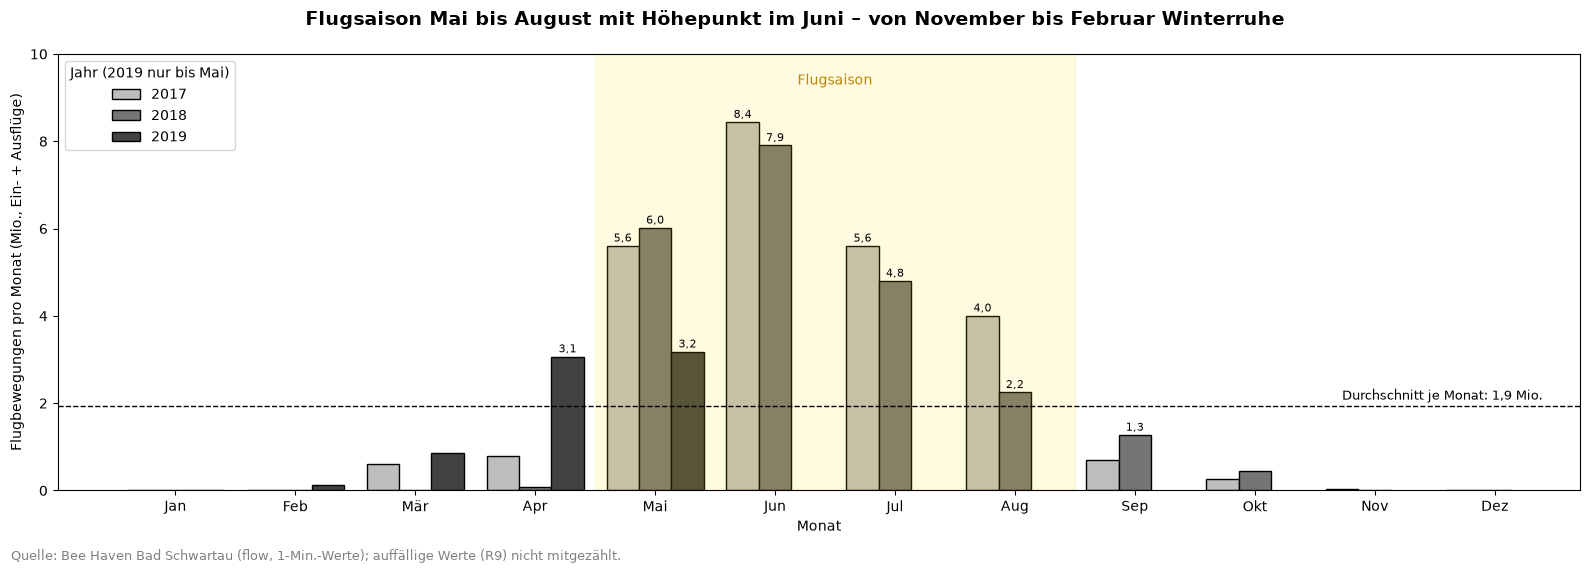

jahr,2017,2018,2019
monat,,,
1,0.00,0.00,0.00
2,0.00,0.00,0.11
3,0.60,0.00,0.87
4,0.78,0.07,3.06
5,5.60,6.01,3.18
6,8.44,7.90,NaN
7,5.60,4.80,NaN
8,4.00,2.25,NaN
9,0.69,1.27,NaN


In [6]:
# --- F2: Flugbewegungen je Monat, Jahre nebeneinander ---
monat = tageswerte["flugbewegungen"].resample("MS").sum() / 1e6          # Monatssumme in Mio.
tab = pd.DataFrame({"jahr": monat.index.year, "monat": monat.index.month, "mio": monat.to_numpy()})
tab = tab.pivot(index="monat", columns="jahr", values="mio")             # Zeilen = Monat, Spalten = Jahr
monatsnamen = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]
schnitt = monat.mean()                                                   # Referenz: durchschnittlicher Monat

fig, ax = plt.subplots(figsize=(16, 5.5))
fig.suptitle("Flugsaison Mai bis August mit Höhepunkt im Juni – von November bis Februar Winterruhe",
             fontsize=14, fontweight="bold")
breite = 0.27
for k, (jahr, farbe) in enumerate(zip(tab.columns, ["#bdbdbd", "#757575", "#424242"])):
    x = np.arange(12) + (k - 1) * breite
    b = ax.bar(x, tab[jahr].reindex(range(1, 13)), width=breite, color=farbe, edgecolor="black", label=str(jahr))
    for xi, v in zip(x, tab[jahr].reindex(range(1, 13))):                 # Werte ab 1 Mio. beschriften
        if v >= 1:
            ax.text(xi, v + 0.1, f"{v:.1f}".replace(".", ","), ha="center", fontsize=8)
ax.axhline(schnitt, color="black", ls="--", lw=1)
ax.text(11.4, schnitt + 0.15, f"Durchschnitt je Monat: {schnitt:.1f}".replace(".", ",") + " Mio.", ha="right", fontsize=9)
ax.axvspan(3.5, 7.5, color="gold", alpha=0.12)
ax.text(5.5, 9.3, "Flugsaison", ha="center", fontsize=10, color="darkgoldenrod")
ax.set_xticks(range(12), monatsnamen)
ax.set(xlabel="Monat", ylabel="Flugbewegungen pro Monat (Mio., Ein- + Ausflüge)", ylim=(0, 10))
ax.legend(title="Jahr (2019 nur bis Mai)")
fig.text(0.01, -0.02, f"Quelle: Bee Haven {ORT['name']} (flow, 1-Min.-Werte); auffällige Werte (R9) nicht mitgezählt.", fontsize=9, color="grey")
plt.tight_layout()
fig.savefig(BILDER / "f2_flugaktivitaet_monat.png", dpi=120, bbox_inches="tight")
plt.show()
tab.round(2)

**Ergebnis:** Grafik (`f2_flugaktivitaet_monat.png`) und Tabelle zeigen die Flugbewegungen je Monat und Jahr (Millionen). Prüfpunkte: Wann beginnt und endet die Saison? Liegt der Höhepunkt im Juni? Unterscheiden sich die Jahre (Wetter, Tracht)?

| Kernaussagen je Stadt | Saison · Höhepunkt · Jahresvergleich |
| :-- | :-- |
| Schwartau | Mai–August · Juni (2017: 8,4 Mio., 2018: 7,9 Mio.) · 2018 später Start und früheres Ende (sehr warmer, trockener Sommer – fachlich zu prüfen), 2019 früher aktiv |
| Würzburg | April–August · Juni 2017 (4,5 Mio.) · ab Juni 2018 Datenlücke; 2019 nur bis 20.05. |

Winterruhe November–Februar an beiden Standorten.

## 6. F3 – Zusammenhang Temperatur und Flugaktivität

**Frage:** Hängt die tägliche Flugaktivität mit der Temperatur zusammen – draußen und im Stock?

**Methode:** Korrelation nach Pearson (r) der Tageswerte: 1 = starker positiver Zusammenhang, 0 = keiner. Korrelation ist **keine Ursache** – Tageslänge, Jahreszeit und Tracht wirken mit.

**Eigene Erwartung:** positiver Zusammenhang; Außentemperatur (N3) aussagekräftiger als Stocktemperatur (Befund E6: Stock ≈ 35 °C Brutnest)

**Erwartung laut Recherche:** Temperatur und Sonnenstrahlung erklärten in einer Feldstudie zusammen 78 % der Schwankung der Flugaktivität [R4].

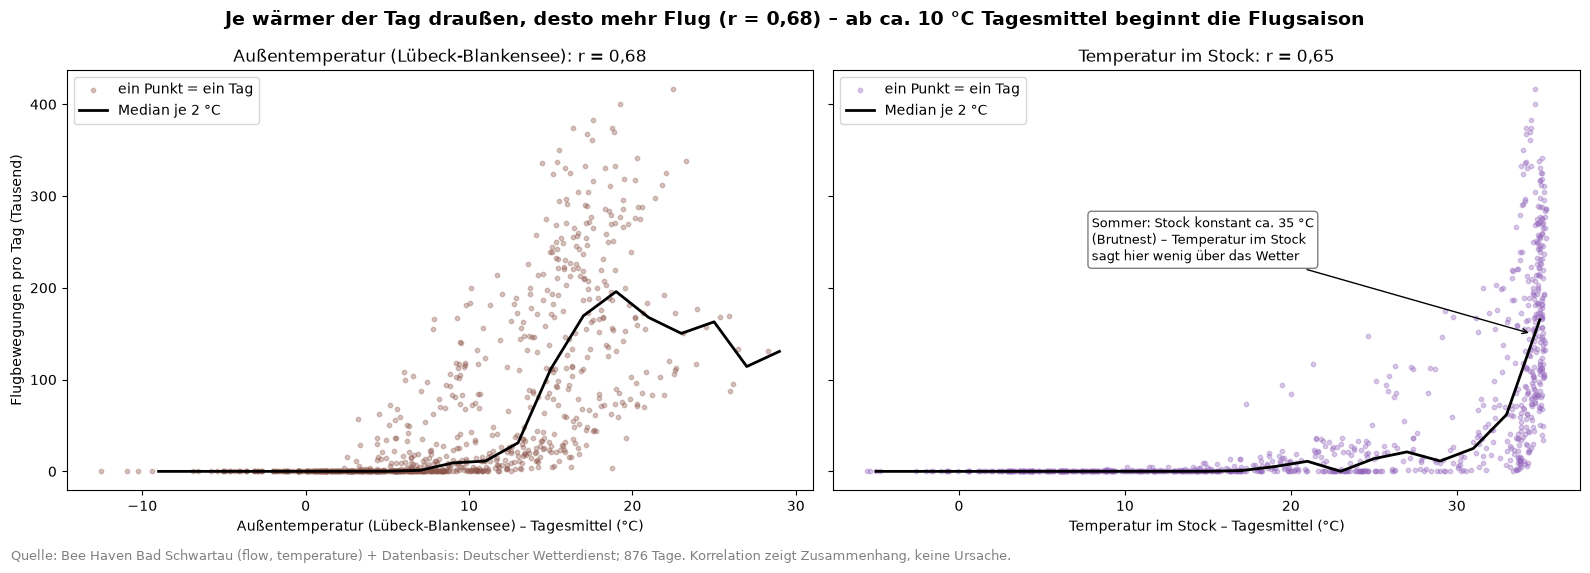

r außen = 0.68 · r Stock = 0.65 · 876 Tage


In [7]:
# --- F3: Flugbewegungen je Tag vs. Außen- und Stocktemperatur ---
wetter_n3 = pd.read_csv(sorted((CLEANED / "wetter").glob(f"wetter_{STADT}_cleaned__*.csv"))[-1], parse_dates=["zeit_utc"])  # Wetter (N3)
STATION_T = wetter_n3["station_temperatur"].mode()[0]                    # häufigste Station der Außentemperatur (Befund W1)
wetter_tag = wetter_n3.set_index("zeit_utc")["aussentemperatur_c"].resample("D").mean()   # Tagesmittel Außentemperatur
paar = tageswerte[["flugbewegungen", "temp_mittel"]].join(wetter_tag.rename("aussen_mittel")).dropna()

fig, ax = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
r_aussen = paar["aussen_mittel"].corr(paar["flugbewegungen"])            # Korrelation außen
r_stock = paar["temp_mittel"].corr(paar["flugbewegungen"])               # Korrelation im Stock
fig.suptitle(f"Je wärmer der Tag draußen, desto mehr Flug (r = {r_aussen:.2f}) – ab ca. 10 °C Tagesmittel beginnt die Flugsaison".replace(".", ",", 1),
             fontsize=14, fontweight="bold")
for a, spalte, r, titel, farbe in [(ax[0], "aussen_mittel", r_aussen, f"Außentemperatur ({STATION_T})", "#8c564b"),
                                   (ax[1], "temp_mittel", r_stock, "Temperatur im Stock", "tab:purple")]:
    a.scatter(paar[spalte], paar["flugbewegungen"] / 1000, s=10, alpha=0.35, color=farbe, label="ein Punkt = ein Tag")
    stufen = pd.cut(paar[spalte], bins=range(-10, 41, 2))                 # 2-Grad-Stufen für die Trendlinie
    median = (paar.groupby(stufen, observed=True)["flugbewegungen"].median() / 1000)
    a.plot([s.mid for s in median.index], median, color="black", lw=2, label="Median je 2 °C")
    a.set(title=f"{titel}: r = {r:.2f}".replace(".", ","), xlabel=f"{titel} – Tagesmittel (°C)")
    a.legend(loc="upper left")
ax[0].set_ylabel("Flugbewegungen pro Tag (Tausend)")
ax[1].annotate("Sommer: Stock konstant ca. 35 °C\n(Brutnest) – Temperatur im Stock\nsagt hier wenig über das Wetter", xy=(34.5, 150),
               xytext=(8, 230), fontsize=9, arrowprops=dict(arrowstyle="->"), bbox=dict(boxstyle="round", fc="white", ec="grey"))
fig.text(0.01, -0.02, f"Quelle: Bee Haven {ORT['name']} (flow, temperature) + Datenbasis: Deutscher Wetterdienst; {len(paar)} Tage. "
         "Korrelation zeigt Zusammenhang, keine Ursache.", fontsize=9, color="grey")
plt.tight_layout()
fig.savefig(BILDER / "f3_temperatur_einflug.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"r außen = {r_aussen:.2f} · r Stock = {r_stock:.2f} · {len(paar)} Tage")

**Ergebnis:** Die Ausgabe nennt die Korrelation r der Tagesflüge mit der Außentemperatur und mit der Stocktemperatur. So liest man sie: Die Außentemperatur zeigt den Wettereinfluss; die Stocktemperatur zeigt eher „Brutsaison ja/nein“, weil das Volk das Brutnest im Sommer bei ca. 35 °C hält (E6). Für Wetter-Aussagen daher die **Außentemperatur** verwenden (A3/A5).

| Kernaussagen je Stadt | r Außentemperatur · r Stocktemperatur |
| :-- | :-- |
| Schwartau | 0,68 · 0,65; unter ca. 10 °C Tagesmittel kaum Flug |
| Würzburg | 0,70 · 0,71 (722 Tage) |

## 6a. Flugdaten mit Tageszeit und Wetter zusammenführen

**Was?** Jede Minute der flow-Daten bekommt: Tageszeit (Tag · Dämmerung · Nacht aus den Sonnenzeiten, N3) und das Wetter der jeweiligen Stunde (Außentemperatur, Niederschlag, Sonnenschein, N3).

**Kennzahl:** **Flugbewegungen pro Minute** = Einflüge + Ausflüge (Betrag). Positiv gemessene Werte sind Einflüge, negative Ausflüge (laut Datensatz-Beschreibung, Pflichtenheft PH-ITS-002 Schritt 2.8).

**Analyse-Regel:** In N2 als auffällig markierte flow-Werte (R9, z. B. Fehlercode 7.999) werden für Summen und Mittelwerte **nicht mitgezählt**; die Daten in Silver bleiben unverändert.

**Kontrollwert:** Minuten wie in N2 (Schwartau 1.256.918, Würzburg 1.027.761), jede mit Tageszeit und Wetter

In [8]:
# --- Neueste Wetter- und Sonnendaten aus N3 laden ---
neueste = lambda ordner: sorted((CLEANED / ordner).glob(f"{ordner}_{STADT}_cleaned__*.csv"))[-1]   # jüngste Version
wetter = pd.read_csv(neueste("wetter"), parse_dates=["zeit_utc"])                                   # stündlich
sonne = pd.read_csv(neueste("sonne"), parse_dates=["daemmerung_beginn_utc", "sonnenaufgang_utc",
                                                    "sonnenuntergang_utc", "daemmerung_ende_utc"])   # täglich

# --- Flugbewegungen je Minute (auffällige Werte aus R9 nicht mitzählen) ---
fl = daten["flow"].copy()                                                          # flow-Daten aus Kapitel 1
fl["zeit_utc"] = pd.to_datetime(fl["zeit_utc"], utc=True)                          # sicherstellen: UTC-Zeit
ein = fl["flow_ein"].where(~fl["flow_ein_auffaellig"])                             # Einflug-Spalte ohne auffällige Werte
aus = fl["flow_aus"].abs().where(~fl["flow_aus_auffaellig"])                       # Ausflug-Spalte als Betrag, ohne auffällige Werte
fl["bewegungen"] = pd.concat([ein, aus], axis=1).sum(axis=1, min_count=1)          # Summe je Minute
ausgeschlossen = int(fl["flow_ein_auffaellig"].sum() + fl["flow_aus_auffaellig"].sum())

# --- Tageszeit je Minute aus den Sonnenzeiten ---
lokal = fl["zeit_utc"].dt.tz_convert(ZEITZONE)                                      # Ortszeit des Standorts
fl["datum"] = lokal.dt.date.astype(str)                                            # Kalendertag (Ortszeit) als Schlüssel
sonne["datum"] = sonne["datum"].astype(str)
fl = fl.merge(sonne, on="datum", how="left")                                       # Sonnenzeiten des Tages anhängen
tag = fl["zeit_utc"].between(fl["sonnenaufgang_utc"], fl["sonnenuntergang_utc"])   # Sonne über dem Horizont
hell = fl["zeit_utc"].between(fl["daemmerung_beginn_utc"], fl["daemmerung_ende_utc"])  # inkl. Dämmerung
fl["tageszeit"] = np.select([tag, hell], ["Tag", "Dämmerung"], "Nacht")

# --- Wetter der jeweiligen Stunde anhängen ---
fl["stunde_utc"] = fl["zeit_utc"].dt.floor("h")                                    # Minute → volle Stunde
fl = fl.merge(wetter[["zeit_utc", "aussentemperatur_c", "niederschlag_mm", "sonnenschein_min"]]
              .rename(columns={"zeit_utc": "stunde_utc"}), on="stunde_utc", how="left")
fl["monat"] = lokal.dt.month                                                       # Monat 1–12
fl["stunde"] = lokal.dt.hour                                                       # Stunde 0–23 (Ortszeit)
fl["temp_stufe"] = pd.cut(fl["aussentemperatur_c"], bins=range(-15, 40, 5), right=False,
                          labels=[f"{u} bis {u + 5} °C" for u in range(-15, 35, 5)])  # 5-Grad-Stufen

print(f"{len(fl):,} Minuten · ohne Wetter: {fl['aussentemperatur_c'].isna().sum()} · ausgeschlossene auffällige Werte: {ausgeschlossen:,}")
print(fl["tageszeit"].value_counts().to_dict())

1,256,918 Minuten · ohne Wetter: 0 · ausgeschlossene auffällige Werte: 24,830
{'Tag': 638733, 'Nacht': 546613, 'Dämmerung': 71572}


**Ergebnis:** Minuten mit Tageszeit und Wetter, ausgeschlossene auffällige Werte und Verteilung Tag/Dämmerung/Nacht (Ausgabe).

| Kernaussagen je Stadt | Minuten · ausgeschlossen (R9) · Tag / Nacht / Dämmerung |
| :-- | :-- |
| Schwartau | 1.256.918 · 24.830 · 637.361 / 546.408 / 71.511 |
| Würzburg | 1.027.761 · 13.002 · 503.752 / 472.802 / 51.207 |

## 6b. A2 – Flugbewegungen nach Tageszeit (Tag · Dämmerung · Nacht) und Monat

**Frage:** Wann am Tag sind die Bienen aktiv, und wie ändert sich das über das Jahr?

**Eigene Erwartung:** fast nur bei Tageslicht; nachts nur Einzelbewegungen

**Erwartung laut Recherche:** Sammlerinnen verlassen morgens den Stock (Waage zeigt dann einen Gewichtsabfall) und kehren bis zum Abend zurück [R5].

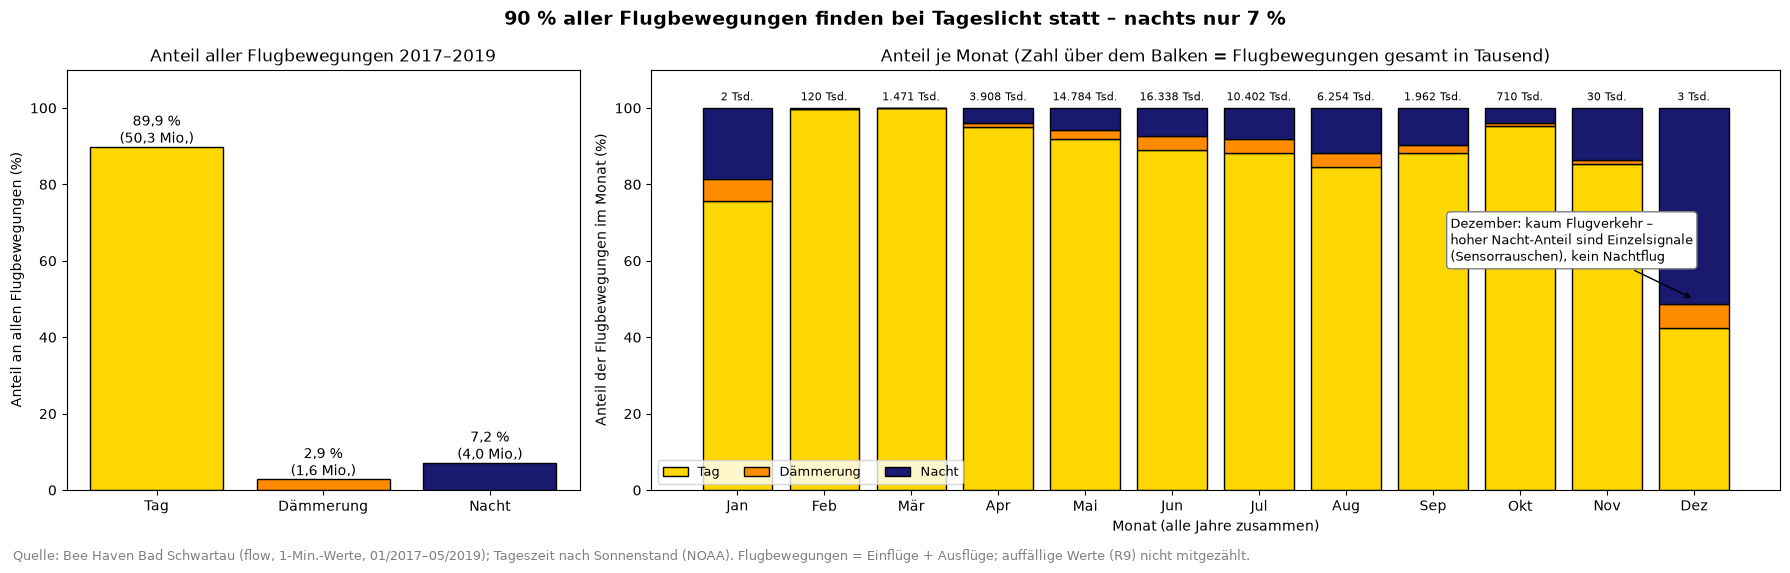

tageszeit,Tag,Dämmerung,Nacht
monat,,,
1,75.6,5.8,18.6
2,99.6,0.1,0.2
3,99.9,0.1,0.1
4,95.0,1.0,4.0
5,91.9,2.3,5.8
6,89.1,3.5,7.3
7,88.2,3.7,8.1
8,84.4,3.7,11.9
9,88.2,2.1,9.7


In [9]:
# --- A2: Anteile nach Tageszeit, gesamt und je Monat ---
farben = {"Tag": "gold", "Dämmerung": "darkorange", "Nacht": "midnightblue"}
monatsnamen = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]
gesamt = fl.groupby("tageszeit")["bewegungen"].sum().reindex(farben)               # Summe je Tageszeit
anteil = gesamt / gesamt.sum() * 100                                               # Anteil in %
je_monat = fl.pivot_table(index="monat", columns="tageszeit", values="bewegungen", aggfunc="sum")[list(farben)]
je_monat_pct = je_monat.div(je_monat.sum(axis=1), axis=0) * 100                    # Anteil je Monat in %
volumen = je_monat.sum(axis=1) / 1e3                                               # Monatsvolumen in Tausend (alle Jahre)

fig, ax = plt.subplots(1, 2, figsize=(18, 5.5), gridspec_kw={"width_ratios": [1, 2.2]})
fig.suptitle(f"{anteil['Tag']:.0f} % aller Flugbewegungen finden bei Tageslicht statt – nachts nur {anteil['Nacht']:.0f} %",
             fontsize=14, fontweight="bold")

balken = ax[0].bar(anteil.index, anteil, color=list(farben.values()), edgecolor="black")
for b, p, n in zip(balken, anteil, gesamt):                                        # Werte an die Balken schreiben
    ax[0].text(b.get_x() + b.get_width() / 2, p + 1, f"{p:.1f} %\n({n / 1e6:.1f} Mio.)".replace(".", ","), ha="center")
ax[0].set(title="Anteil aller Flugbewegungen 2017–2019", ylabel="Anteil an allen Flugbewegungen (%)", ylim=(0, 110))

unten = np.zeros(12)
for tz, farbe in farben.items():                                                   # gestapelte 100-%-Balken je Monat
    ax[1].bar(monatsnamen, je_monat_pct[tz], bottom=unten, color=farbe, edgecolor="black", label=tz)
    unten += je_monat_pct[tz].to_numpy()
for i, v in enumerate(volumen):                                                    # Monatsvolumen über die Balken
    ax[1].text(i, 102, f"{v:,.0f} Tsd.".replace(",", "."), ha="center", fontsize=8)
ax[1].set(title="Anteil je Monat (Zahl über dem Balken = Flugbewegungen gesamt in Tausend)",
          ylabel="Anteil der Flugbewegungen im Monat (%)", xlabel="Monat (alle Jahre zusammen)", ylim=(0, 110))
ax[1].legend(loc="lower left", ncol=3, fontsize=9)
ax[1].annotate("Dezember: kaum Flugverkehr –\nhoher Nacht-Anteil sind Einzelsignale\n(Sensorrauschen), kein Nachtflug",
               xy=(11, 50), xytext=(8.2, 60), fontsize=9, arrowprops=dict(arrowstyle="->"),
               bbox=dict(boxstyle="round", fc="white", ec="grey"))
fig.text(0.01, -0.02, f"Quelle: Bee Haven {ORT['name']} (flow, 1-Min.-Werte, 01/2017–05/2019); Tageszeit nach Sonnenstand (NOAA). "
         "Flugbewegungen = Einflüge + Ausflüge; auffällige Werte (R9) nicht mitgezählt.", fontsize=9, color="grey")
plt.tight_layout()
plt.savefig(BILDER / "a2_flug_tageszeit.png", dpi=120, bbox_inches="tight")
plt.show()
je_monat_pct.round(1)

**Ergebnis:** Grafik (`a2_flug_tageszeit.png`) und Tabelle zeigen den Anteil der Flugbewegungen bei Tag, in der Dämmerung und nachts je Monat. So liest man sie: In Monaten mit wenig Flugverkehr (Dezember/Januar) schwanken die Anteile stark – ein hoher Nachtanteil besteht dann aus Einzelsignalen und ist kein echter Nachtflug.

| Kernaussagen je Stadt | Anteile · Besonderheit |
| :-- | :-- |
| Schwartau | 89,9 % Tag, 2,9 % Dämmerung, 7,2 % Nacht; Februar–April und Oktober über 95 % bei Tag; Juli–September 8–12 % nachts |
| Würzburg | Mai–Oktober 83–92 % bei Tag, Juni/Juli 11–13 % nachts; Februar–April und November über 97 % bei Tag |

Nachtbewegungen im Sommer: in warmen Nächten Bewegungen am Flugloch (z. B. Belüften, späte Heimkehrer) – fachlich noch zu belegen.

## 6c. A3 + A5 – Flugbewegungen nach Außentemperatur (5-Grad-Stufen)

**Frage:** Ab welcher Außentemperatur fliegen die Bienen, und fliegen sie bei Hitze weniger? A5 betrachtet nur **12–15 Uhr**, damit Wärme nicht mit Tageszeit vermischt wird.

**Eigene Erwartung:** kaum Flug unter 10 °C, Maximum im warmen Bereich, bei großer Hitze Rückgang

**Erwartung laut Recherche:** Flugbeginn in Studien je nach Art und Region bei ca. 10 °C (teils erst 15–18 °C), Optimum 20–30 °C; über ca. 33–35 °C stellen viele Pflanzen die Nektarbildung ein [R3].

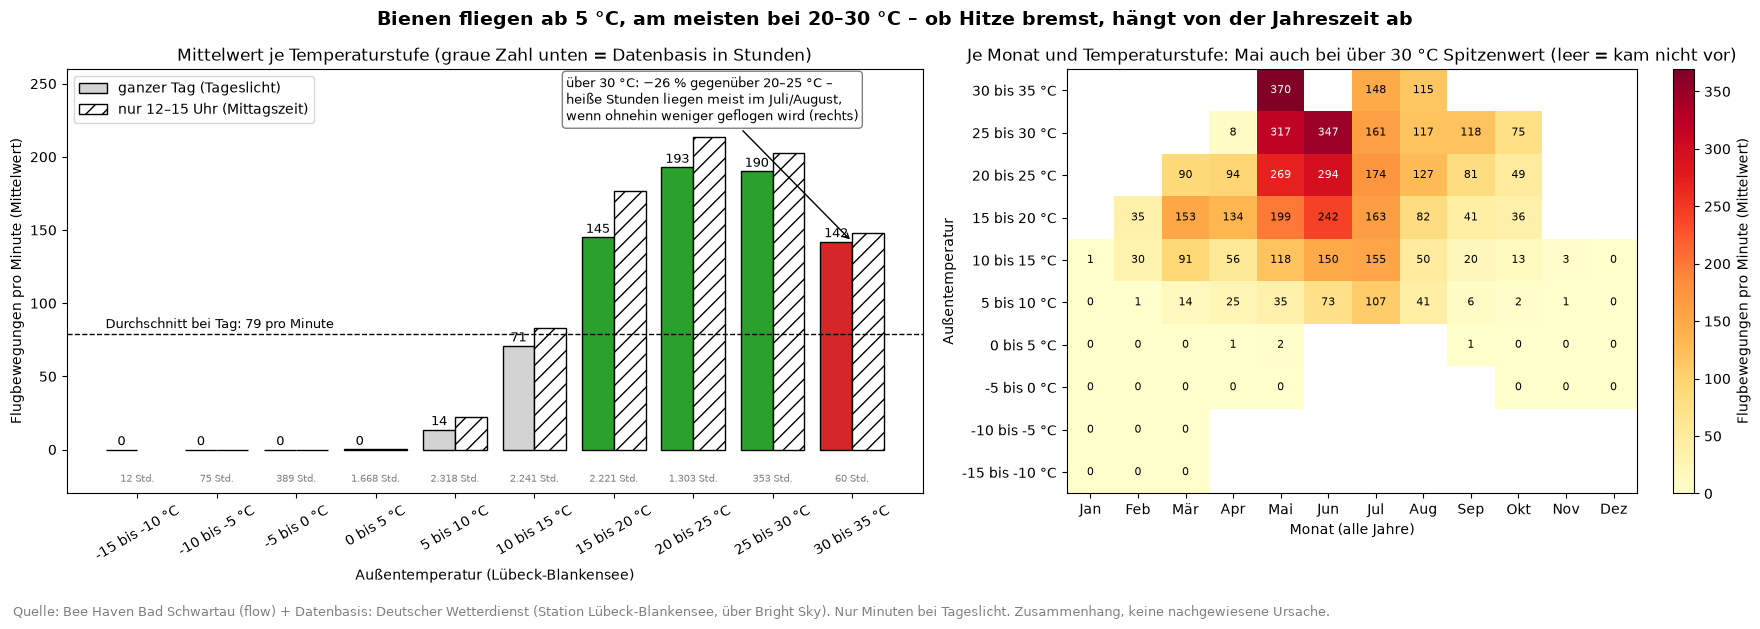

,ganzer_tag,mittag_12_15,stunden
temp_stufe,,,
-15 bis -10 °C,0.0,NaN,11.8
-10 bis -5 °C,0.0,0.0,74.9
-5 bis 0 °C,0.0,0.0,389.3
0 bis 5 °C,0.2,0.2,1668.3
5 bis 10 °C,13.7,21.9,2318.0
10 bis 15 °C,70.9,83.0,2241.3
15 bis 20 °C,145.1,176.4,2221.5
20 bis 25 °C,192.9,213.7,1303.1
25 bis 30 °C,190.2,202.8,352.7


In [10]:
# --- A3/A5: mittlere Flugbewegungen pro Minute je Temperaturstufe (nur bei Tageslicht) ---
tag_df = fl[fl["tageszeit"] == "Tag"]                                              # nur Tageslicht
a3 = tag_df.groupby("temp_stufe", observed=True)["bewegungen"].agg(["mean", "size"])  # alle Tagesstunden
a5 = tag_df[tag_df["stunde"].between(12, 14)].groupby("temp_stufe", observed=True)["bewegungen"].mean()  # 12:00–14:59
schnitt = tag_df["bewegungen"].mean()                                              # Referenz: Durchschnitt bei Tag
heat = tag_df.pivot_table(index="temp_stufe", columns="monat", values="bewegungen", aggfunc="mean", observed=True)

fig, ax = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [1.2, 1]})
spitze = a3["mean"].idxmax()
fig.suptitle("Bienen fliegen ab 5 °C, am meisten bei 20–30 °C – ob Hitze bremst, hängt von der Jahreszeit ab",
             fontsize=14, fontweight="bold")

x = np.arange(len(a3))
farbe = ["lightgrey" if v < schnitt else "tab:green" for v in a3["mean"]]
farbe[-1] = "tab:red"                                                              # Hitzestufe hervorheben
ax[0].bar(x - 0.2, a3["mean"], width=0.4, color=farbe, edgecolor="black", label="ganzer Tag (Tageslicht)")
ax[0].bar(x + 0.2, a5.reindex(a3.index), width=0.4, color="white", edgecolor="black", hatch="//", label="nur 12–15 Uhr (Mittagszeit)")
ax[0].axhline(schnitt, color="black", ls="--", lw=1)
ax[0].text(-0.4, schnitt + 4, f"Durchschnitt bei Tag: {schnitt:.0f} pro Minute", ha="left", fontsize=9)
for i, (m, n) in enumerate(zip(a3["mean"], a3["size"])):                           # Wert und Stichprobengröße
    ax[0].text(i - 0.2, m + 3, f"{m:.0f}", ha="center", fontsize=9)
    ax[0].text(i, -22, f"{n / 60:,.0f} Std.".replace(",", "."), ha="center", fontsize=7, color="grey")
ax[0].annotate("über 30 °C: −26 % gegenüber 20–25 °C –\nheiße Stunden liegen meist im Juli/August,\nwenn ohnehin weniger geflogen wird (rechts)", xy=(len(a3) - 1, a3["mean"].iloc[-1]),
               xytext=(len(a3) - 4.6, 225), fontsize=9, arrowprops=dict(arrowstyle="->"), bbox=dict(boxstyle="round", fc="white", ec="grey"))
ax[0].set_xticks(x, a3.index, rotation=30)
ax[0].set(title="Mittelwert je Temperaturstufe (graue Zahl unten = Datenbasis in Stunden)",
          xlabel=f"Außentemperatur ({STATION_T})", ylabel="Flugbewegungen pro Minute (Mittelwert)", ylim=(-30, 260))
ax[0].legend(loc="upper left")

bild = ax[1].imshow(heat, aspect="auto", cmap="YlOrRd", origin="lower")            # Heatmap Temperaturstufe × Monat
for (i, j), v in np.ndenumerate(heat.to_numpy()):                                  # Werte in die Felder schreiben
    if not np.isnan(v):
        ax[1].text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="black" if v < 250 else "white")
ax[1].set_xticks(range(12), monatsnamen)
ax[1].set_yticks(range(len(heat)), heat.index)
ax[1].set(title="Je Monat und Temperaturstufe: Mai auch bei über 30 °C Spitzenwert (leer = kam nicht vor)", xlabel="Monat (alle Jahre)", ylabel="Außentemperatur")
fig.colorbar(bild, ax=ax[1], label="Flugbewegungen pro Minute (Mittelwert)")
fig.text(0.01, -0.03, f"Quelle: Bee Haven {ORT['name']} (flow) + Datenbasis: Deutscher Wetterdienst (Station {STATION_T}, über Bright Sky). "
         "Nur Minuten bei Tageslicht. Zusammenhang, keine nachgewiesene Ursache.", fontsize=9, color="grey")
plt.tight_layout()
plt.savefig(BILDER / "a3_a5_flug_temperatur.png", dpi=120, bbox_inches="tight")
plt.show()
pd.DataFrame({"ganzer_tag": a3["mean"], "mittag_12_15": a5, "stunden": a3["size"] / 60}).round(1)

**Ergebnis:** Grafik (`a3_a5_flug_temperatur.png`) und Tabelle zeigen die Flugbewegungen pro Minute je 5-Grad-Stufe (ganzer Tag und nur 12–15 Uhr) und die Zahl der Stunden je Stufe. So liest man sie: Stufen mit wenigen Stunden (z. B. über 30 °C) sind unsicher; die Heatmap Monat × Temperatur zeigt, ob ein Effekt nur von der Jahreszeit kommt.

| Kernaussagen je Stadt | Flugbeginn · Maximum · über 30 °C |
| :-- | :-- |
| Schwartau | ab 5 °C, ab 10 °C deutlicher Anstieg · 20–30 °C (ca. 190 pro Min., 2,4 × Tagesdurchschnitt 79) · im Schnitt −26 % (12–15 Uhr −31 %), aber im Mai bei über 30 °C Höchstwert → Rückgang kommt von der Jahreszeit (heiße Stunden meist Juli/August); Hitze-Effekt nicht belegt (ca. 60 Stunden) |
| Würzburg | ab 5 °C, ab 10 °C deutlicher Anstieg · steigt bis 30–35 °C (166 pro Min.) · kein Rückgang, aber nur 37 Stunden über 30 °C |

Bei gleicher Temperatur fliegen die Bienen im Mai/Juni mehr als im August/September → neben der Temperatur wirken Jahreszeit und Tracht (Blütenangebot). Einzelgrafiken können täuschen; kombinierte Auswertungen (A7–A10, Machine Learning) sind nötig.

## 6d. A6 + A4 – Regen, Sonnenschein und Tagesverlauf

**Frage:** Wie stark bremsen Regen und fehlende Sonne den Flug? Wie verteilt sich der Flug über Stunde und Monat?

**Eigene Erwartung:** bei Regen deutlich weniger Flug; Tagesverlauf folgt der Tageslänge

**Erwartung laut Recherche:** Regen und hohe Luftfeuchte gehen mit geringerer Aktivität einher; Sonnenstrahlung erklärt je nach Studie 40–87 % der Schwankung (R² = 0,40–0,87) [R3].

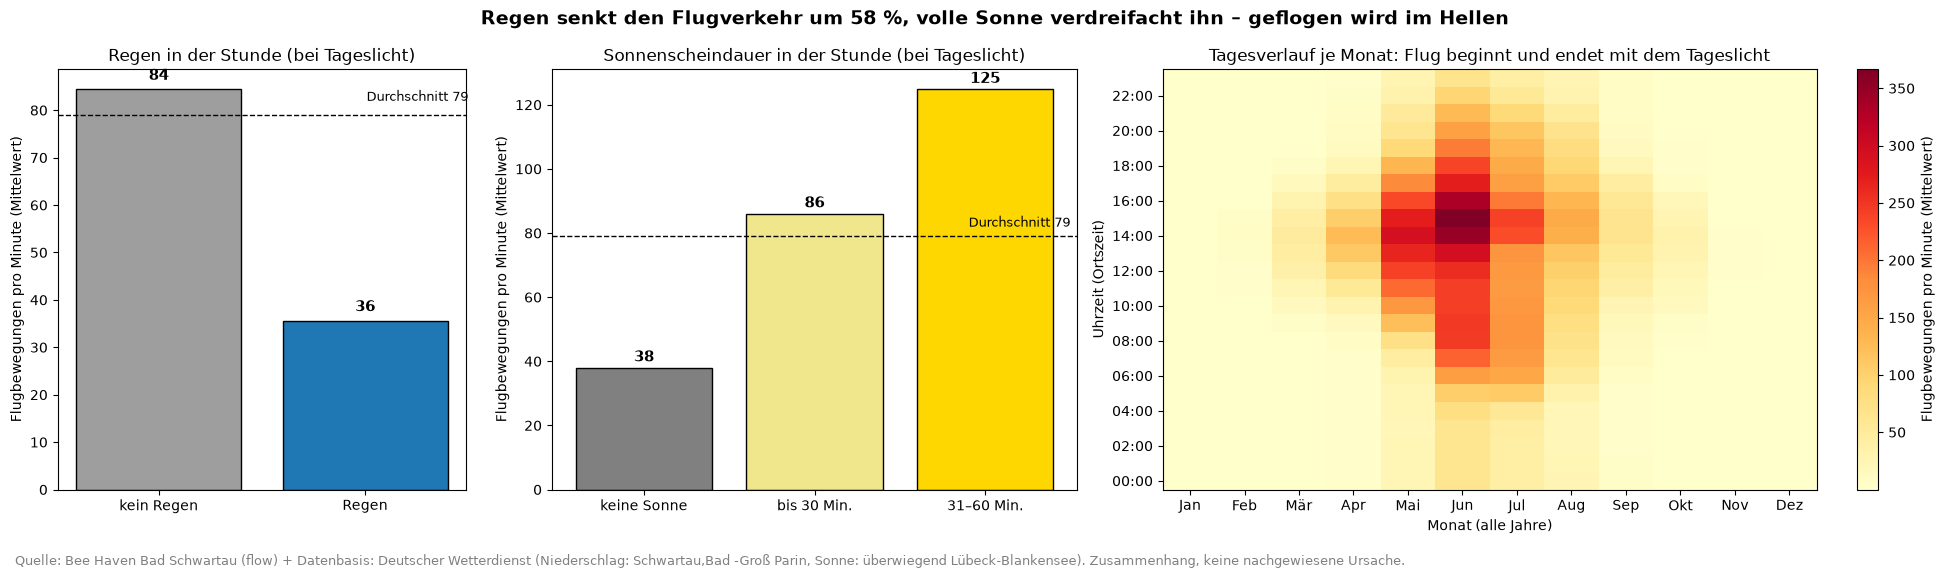

kein Regen      84.4
Regen           35.6
keine Sonne     38.0
bis 30 Min.     86.0
31–60 Min.     124.8
Name: bewegungen, dtype: float64

In [11]:
# --- A6: Regen und Sonnenschein (nur Tageslicht) · A4: Stunde × Monat ---
regen = tag_df.groupby(tag_df["niederschlag_mm"] > 0)["bewegungen"].mean().rename({False: "kein Regen", True: "Regen"})
sonnen_klasse = pd.cut(tag_df["sonnenschein_min"], [-1, 0, 30, 60], labels=["keine Sonne", "bis 30 Min.", "31–60 Min."])
sonnig = tag_df.groupby(sonnen_klasse, observed=True)["bewegungen"].mean()
stunde_monat = fl.pivot_table(index="stunde", columns="monat", values="bewegungen", aggfunc="mean")

fig, ax = plt.subplots(1, 3, figsize=(20, 5.5), gridspec_kw={"width_ratios": [0.7, 0.9, 1.4]})
rueck = (1 - regen["Regen"] / regen["kein Regen"]) * 100
fig.suptitle(f"Regen senkt den Flugverkehr um {rueck:.0f} %, volle Sonne verdreifacht ihn – geflogen wird im Hellen",
             fontsize=14, fontweight="bold")
for a, werte, farben, titel in [(ax[0], regen, ["#9e9e9e", "#1f77b4"], "Regen in der Stunde (bei Tageslicht)"),
                                (ax[1], sonnig, ["grey", "khaki", "gold"], "Sonnenscheindauer in der Stunde (bei Tageslicht)")]:
    b = a.bar(werte.index.astype(str), werte, color=farben, edgecolor="black")
    for rect, v in zip(b, werte):
        a.text(rect.get_x() + rect.get_width() / 2, v + 2, f"{v:.0f}", ha="center", fontsize=11, fontweight="bold")
    a.axhline(schnitt, color="black", ls="--", lw=1)
    a.text(len(werte) - 0.5, schnitt + 3, f"Durchschnitt {schnitt:.0f}", ha="right", fontsize=9)
    a.set(title=titel, ylabel="Flugbewegungen pro Minute (Mittelwert)")

bild = ax[2].imshow(stunde_monat, aspect="auto", cmap="YlOrRd", origin="lower")
ax[2].set_xticks(range(12), monatsnamen)
ax[2].set_yticks(range(0, 24, 2), [f"{h:02d}:00" for h in range(0, 24, 2)])
ax[2].set(title="Tagesverlauf je Monat: Flug beginnt und endet mit dem Tageslicht", xlabel="Monat (alle Jahre)", ylabel="Uhrzeit (Ortszeit)")
fig.colorbar(bild, ax=ax[2], label="Flugbewegungen pro Minute (Mittelwert)")
fig.text(0.01, -0.03, f"Quelle: Bee Haven {ORT['name']} (flow) + Datenbasis: Deutscher Wetterdienst (Niederschlag: {wetter['station_niederschlag'].mode()[0]}, "
         f"Sonne: überwiegend {wetter['station_sonnenschein'].mode()[0]}). "
         "Zusammenhang, keine nachgewiesene Ursache.", fontsize=9, color="grey")
plt.tight_layout()
plt.savefig(BILDER / "a4_a6_flug_regen_sonne_stunde.png", dpi=120, bbox_inches="tight")
plt.show()
pd.concat([regen, sonnig]).round(1)

**Ergebnis:** Grafik (`a4_a6_flug_regen_sonne_stunde.png`) und Ausgabe zeigen Flugbewegungen pro Minute mit/ohne Regen und nach Sonnenscheindauer der Stunde sowie den Tagesverlauf (Stunde × Monat).

| Kernaussagen je Stadt | Regen · Sonne (keine / bis 30 Min. / 31–60 Min.) |
| :-- | :-- |
| Schwartau | 36 statt 84 (−58 %) · 38 / 86 / 125 → volle Sonne ca. 3 × |
| Würzburg | 11 statt 37 (−69 %) · 11 / 34 / 61 → volle Sonne ca. 5 × |

**Tagesverlauf:** Der Flug beginnt und endet mit dem Tageslicht und verschiebt sich über das Jahr wie Sonnenauf- und -untergang (N3); Höhepunkt am frühen Nachmittag. **Einschränkung:** Regen, Sonne und Temperatur hängen zusammen (Regen = meist kühler und bewölkt) – die Einzelwirkung lässt sich so nicht trennen (Folgeprojekt Machine Learning).

## 6a. Weitere Wettergrößen: Feuchte, Strahlung, Wind, Luftdruck (A7–A10)

**Warum?** N3 liefert seit 29.09.2026 zusätzlich Taupunkt, Sonnenstrahlung, Windböen und Luftdruck (Umfang wie Kurs-Notebook 02).

**Vorgehen (gleiche Bedingungen):** Wetter ist stündlich → Flug je Stunde (Mittel der Minuten, nur Stunden mit mind. 50 Flugminuten). Weil feuchte, windige oder tiefdruckreiche Stunden meist im Winter, nachts oder bei Regen liegen, wird jede Größe **unter vergleichbaren Bedingungen** betrachtet: Tag (Sonnenstand N3), kein Regen, 15–25 °C, April–September. Zum Vergleich zeigen Kreise alle Tagesstunden ohne Filter – der Unterschied zeigt, wie stark Jahreszeit und Tageszeit sonst täuschen.

**Eigene Erwartung (Rechnung):** Tage × ca. 12 Stunden Tageslicht ≈ 10.000 Tagesstunden; davon einige tausend vergleichbar

In [12]:
# --- Stundentabelle: Flug je Stunde + Wetter der Stunde (Grundlage A7–A10) ---
w_std = wetter.copy()                                                              # stündliches Wetter aus N3
w_std["zeit_utc"] = pd.to_datetime(w_std["zeit_utc"], utc=True)                    # sicherstellen: UTC-Zeit
w_std["druck_tendenz_3h"] = w_std["luftdruck_hpa"].diff(3)                         # Luftdruckänderung der letzten 3 Stunden (hPa)
std = (fl.groupby("stunde_utc").agg(bewegungen=("bewegungen", "mean"), minuten=("bewegungen", "count"))
         .reset_index().rename(columns={"stunde_utc": "zeit_utc"}))                # Flug je Stunde (Mittel der Minuten)
std = std.merge(w_std, on="zeit_utc", how="inner")                                 # Wetter der Stunde anhängen
std = std[std["minuten"] >= 50].copy()                                             # nur Stunden mit mind. 50 Flugminuten
std["monat"] = std["zeit_utc"].dt.tz_convert(ZEITZONE).dt.month                    # Monat in Ortszeit
std["jahreszeit"] = std["monat"].map({3: "Frühling", 4: "Frühling", 5: "Frühling", 6: "Sommer", 7: "Sommer", 8: "Sommer",
                                      9: "Herbst", 10: "Herbst", 11: "Herbst"}).fillna("Winter")  # meteorologische Jahreszeiten
std["abstand_taupunkt_c"] = std["aussentemperatur_c"] - std["taupunkt_c"]          # klein = feuchte Luft (Tau, Nebel), groß = trocken
std["strahlung_wm2"] = std["sonnenstrahlung_kwh_m2"] * 1000                        # kWh/m² je Stunde -> mittlere Leistung in W/m²

# --- „Gleiche Bedingungen“ als Maske ---
tag_std = std["tageszeit"] == "Tag"                                                # Sonne über dem Horizont
vergleichbar = tag_std & (std["niederschlag_mm"] == 0) & std["aussentemperatur_c"].between(15, 25) & std["monat"].between(4, 9)
basis = std.loc[vergleichbar, "bewegungen"].mean()                                 # Referenzwert unter gleichen Bedingungen

def je_klasse(spalte, grenzen, maske):
    """Mittlere Flugbewegungen pro Minute und Anzahl Stunden je Werteklasse (nur Zeilen der Maske)."""
    klasse = pd.cut(std.loc[maske, spalte], grenzen)
    gruppe = std[maske].groupby(klasse, observed=True)["bewegungen"]
    return pd.DataFrame({"bewegungen": gruppe.mean(), "stunden": gruppe.size()})

print(f"{len(std):,} Stunden · davon Tag: {tag_std.sum():,} · vergleichbar: {vergleichbar.sum():,} · Referenz: {basis:.0f} Bewegungen/Min.")

20,940 Stunden · davon Tag: 10,627 · vergleichbar: 3,176 · Referenz: 170 Bewegungen/Min.


**Ergebnis:** Stunden mit Flug- und Wetterdaten, davon bei Tag und unter gleichen Bedingungen (Tag, kein Regen, 15–25 °C, April–September), sowie die Referenz (Flugbewegungen pro Minute unter gleichen Bedingungen).

| Kernaussagen je Stadt | Stunden · Tag · vergleichbar · Referenz |
| :-- | :-- |
| Schwartau | 20.940 · 10.627 · 3.176 · 170 pro Min. (alle Tagesstunden: 79) |
| Würzburg | 17.121 · 8.364 · 1.947 · 83 pro Min. |

### A7 – Luftfeuchte: Abstand zwischen Temperatur und Taupunkt

**Warum Abstand statt Taupunkt?** Der Taupunkt allein steigt mit der Temperatur (Sommer = hoher Taupunkt). Aussagekräftig für „feucht“ ist der **Abstand Temperatur − Taupunkt**: unter ca. 2 °C ist die Luft fast gesättigt (Tau, Nebel, nasse Blüten), über 10 °C trocken.

**Gleiche Bedingungen:** Die Feuchte schwankt zwischen Tag und Nacht und zwischen den Jahreszeiten (Frühling/Herbst feuchter) → getrennt nach **Jahreszeit** und **Tag/Dämmerung**; nur ohne Regen und bei 10–25 °C.

**Eigene Erwartung:** feuchte Luft → weniger Flug, in der Dämmerung stärker als am Tag

**Erwartung laut Recherche:** negative Beziehung zwischen Luftfeuchte und Bienenaktivität; günstige Luftfeuchte je nach Tracht ca. 54–70 % [R3].

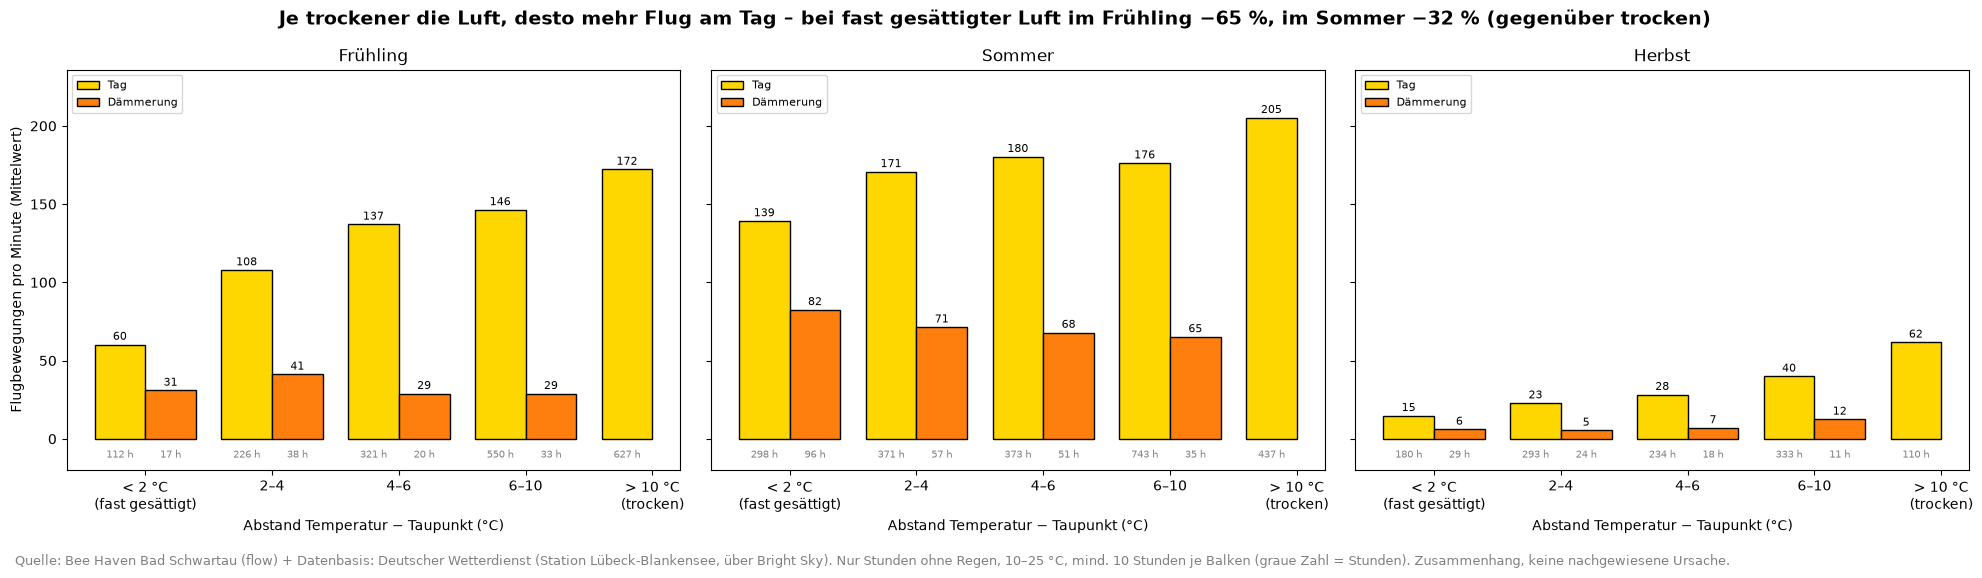

bewegungen                                              \
jahreszeit           Frühling           Sommer           Herbst             
tageszeit                 Tag Dämmerung    Tag Dämmerung    Tag Dämmerung   
abstand_taupunkt_c                                                          
(0, 2]                   60.0      31.0  139.0      82.0   15.0       6.0   
(2, 4]                  108.0      41.0  171.0      71.0   23.0       5.0   
(4, 6]                  137.0      29.0  180.0      68.0   28.0       7.0   
(6, 10]                 146.0      29.0  176.0      65.0   40.0      12.0   
(10, 30]                172.0       NaN  205.0       NaN   62.0       NaN   

                    stunden                                              
jahreszeit         Frühling           Sommer           Herbst            
tageszeit               Tag Dämmerung    Tag Dämmerung    Tag Dämmerung  
abstand_taupunkt_c                                                       
(0, 2]                112.0      17.0  298.0      96.0  180.0      29.0  
(2, 4]                226.0      38.0  371.0      57.0  293.0      24.0  
(4, 6]                321.0      20.0  373.0      51.0  234.0      18.0  
(6, 10]               550.0      33.0  743.0      35.0  333.0      11.0  
(10, 30]              627.0       NaN  437.0       NaN  110.0       NaN

In [13]:
# --- A7: Flug nach Feuchte-Abstand, getrennt nach Jahreszeit und Tag/Dämmerung ---
grenzen = [0, 2, 4, 6, 10, 30]                                                     # Klassen Temperatur − Taupunkt (°C)
maske_a7 = std["tageszeit"].isin(["Tag", "Dämmerung"]) & (std["niederschlag_mm"] == 0) & std["aussentemperatur_c"].between(10, 25)
fig, ax = plt.subplots(1, 3, figsize=(20, 5.5), sharey=True)
ergebnis_a7 = {}
for a, jz in zip(ax, ["Frühling", "Sommer", "Herbst"]):
    for k, (tz, farbe) in enumerate([("Tag", "gold"), ("Dämmerung", "tab:orange")]):
        t = je_klasse("abstand_taupunkt_c", grenzen, maske_a7 & (std["jahreszeit"] == jz) & (std["tageszeit"] == tz))
        t = t[t["stunden"] >= 10]                                                  # Klassen mit weniger als 10 Stunden weglassen
        ergebnis_a7[(jz, tz)] = t
        x = np.array([grenzen.index(int(i.left)) for i in t.index]) + (k - 0.5) * 0.4
        a.bar(x, t["bewegungen"], width=0.4, color=farbe, edgecolor="black", label=tz)
        for xi, (v, n) in zip(x, t.to_numpy()):
            a.text(xi, v + 3, f"{v:.0f}", ha="center", fontsize=8)
            a.text(xi, -12, f"{n:.0f} h", ha="center", fontsize=7, color="grey")
    a.set_xticks(range(len(grenzen) - 1), ["< 2 °C\n(fast gesättigt)", "2–4", "4–6", "6–10", "> 10 °C\n(trocken)"])
    a.set(title=jz, xlabel="Abstand Temperatur − Taupunkt (°C)", ylim=(-20, None))
    a.legend(loc="upper left", fontsize=8)
ax[0].set_ylabel("Flugbewegungen pro Minute (Mittelwert)")
ax[0].set_ylim(-20, max(t["bewegungen"].max() for t in ergebnis_a7.values()) * 1.15)   # Platz für die Beschriftung
fig.suptitle("Je trockener die Luft, desto mehr Flug am Tag – bei fast gesättigter Luft im Frühling −65 %, im Sommer −32 % (gegenüber trocken)",
             fontsize=14, fontweight="bold")
fig.text(0.01, -0.03, f"Quelle: Bee Haven {ORT['name']} (flow) + Datenbasis: Deutscher Wetterdienst (Station {STATION_T}, über Bright Sky). "
         "Nur Stunden ohne Regen, 10–25 °C, mind. 10 Stunden je Balken (graue Zahl = Stunden). Zusammenhang, keine nachgewiesene Ursache.", fontsize=9, color="grey")
plt.tight_layout()
plt.savefig(BILDER / "a7_flug_feuchte.png", dpi=120, bbox_inches="tight")
plt.show()
pd.concat(ergebnis_a7, names=["jahreszeit", "tageszeit"]).round(0).unstack([0, 1])

**Ergebnis (A7):** Grafik (`a7_flug_feuchte.png`) und Tabelle zeigen Flugbewegungen pro Minute je Abstand Temperatur − Taupunkt, getrennt nach Jahreszeit und Tag/Dämmerung, mit der Zahl der Stunden. Balken mit wenigen Stunden (unter ca. 30) sind nur ein Hinweis.

| Kernaussagen je Stadt | Tag: fast gesättigte Luft (< 2 °C) gegenüber trockener Luft (> 10 °C) |
| :-- | :-- |
| Schwartau | Frühling 60 statt 172 (−65 %), Sommer 139 statt 205 (−32 %), Herbst 15 statt 62 (−76 %, niedriges Niveau); Dämmerung uneinheitlich |
| Würzburg | Frühling 36 statt 75 (−52 %), Sommer 49 statt 98 (−50 %), Herbst 20 statt 27; Dämmerung uneinheitlich |

**Vergleich mit der Recherche:** Die negative Beziehung zwischen Feuchte und Aktivität [R3] wird am Tag an beiden Standorten bestätigt. Einschränkung: Feuchte Stunden sind oft auch bewölkt (weniger Strahlung, A8) – die Einzelwirkung der Feuchte ist damit nicht getrennt.

### A8 – Sonnenstrahlung und Hitze: gleiche Wirkung?

**Warum?** Sonnige Stunden sind meist auch warme Stunden – die Heatmap trennt beides: Zeilen = Temperatur, Spalten = Strahlung. Nur Tag ohne Regen.

**Eigene Erwartung:** Sonne fördert den Flug, große Hitze bremst ihn

**Erwartung laut Recherche:** Aktivität steigt mit der Strahlung zunächst linear, nimmt aber **über ca. 460 W/m²** insgesamt wieder ab; Temperatur wirkt nahezu linear [R3] (Burrill & Dietz 1981, dort zitiert).

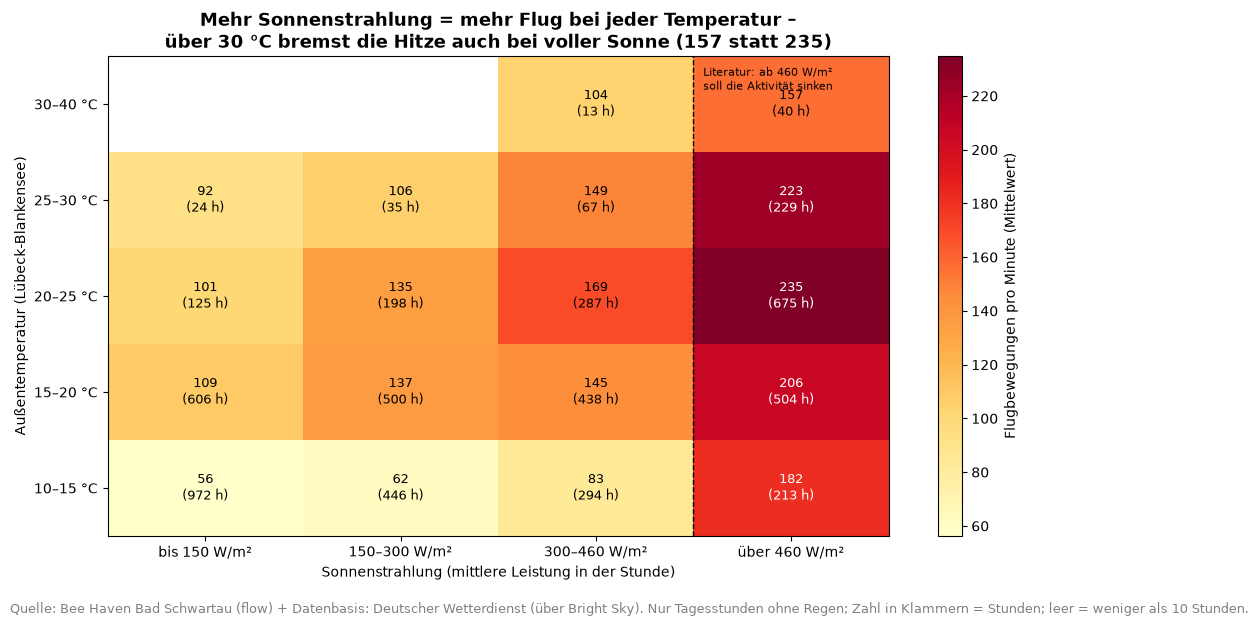

strahlung_wm2,bis 150,150–300,300–460,über 460
aussentemperatur_c,,,,
"(10, 15]",56.0,62.0,83.0,182.0
"(15, 20]",109.0,137.0,145.0,206.0
"(20, 25]",101.0,135.0,169.0,235.0
"(25, 30]",92.0,106.0,149.0,223.0
"(30, 40]",NaN,NaN,104.0,157.0


In [14]:
# --- A8: Heatmap Temperatur × Sonnenstrahlung (Tag, kein Regen) ---
maske_a8 = tag_std & (std["niederschlag_mm"] == 0)
t_kl = pd.cut(std.loc[maske_a8, "aussentemperatur_c"], [10, 15, 20, 25, 30, 40])
s_kl = pd.cut(std.loc[maske_a8, "strahlung_wm2"], [-1, 150, 300, 460, 1000], labels=["bis 150", "150–300", "300–460", "über 460"])
mittel = std[maske_a8].pivot_table(index=t_kl, columns=s_kl, values="bewegungen", aggfunc="mean", observed=True)
anzahl = std[maske_a8].pivot_table(index=t_kl, columns=s_kl, values="bewegungen", aggfunc="size", observed=True)
mittel = mittel.where(anzahl >= 10)                                                # Felder mit weniger als 10 Stunden leer lassen

fig, ax = plt.subplots(figsize=(11, 6))
bild = ax.imshow(mittel, cmap="YlOrRd", origin="lower", aspect="auto")
for (i, j), v in np.ndenumerate(mittel.to_numpy()):
    if not np.isnan(v):
        ax.text(j, i, f"{v:.0f}\n({anzahl.iloc[i, j]:.0f} h)", ha="center", va="center", fontsize=9,
                color="white" if v > 180 else "black")
ax.set_xticks(range(mittel.shape[1]), [f"{c} W/m²" for c in mittel.columns])
ax.set_yticks(range(mittel.shape[0]), [f"{i.left:.0f}–{i.right:.0f} °C" for i in mittel.index])
ax.axvline(2.5, color="black", ls="--", lw=1)
ax.text(2.55, mittel.shape[0] - 0.6, "Literatur: ab 460 W/m²\nsoll die Aktivität sinken", fontsize=8, va="top")
ax.set(xlabel="Sonnenstrahlung (mittlere Leistung in der Stunde)", ylabel=f"Außentemperatur ({STATION_T})")
fig.colorbar(bild, ax=ax, label="Flugbewegungen pro Minute (Mittelwert)")
ax.set_title("Mehr Sonnenstrahlung = mehr Flug bei jeder Temperatur –\nüber 30 °C bremst die Hitze auch bei voller Sonne (157 statt 235)", fontsize=13, fontweight="bold")
fig.text(0.01, -0.03, f"Quelle: Bee Haven {ORT['name']} (flow) + Datenbasis: Deutscher Wetterdienst (über Bright Sky). "
         "Nur Tagesstunden ohne Regen; Zahl in Klammern = Stunden; leer = weniger als 10 Stunden.", fontsize=9, color="grey")
plt.tight_layout()
plt.savefig(BILDER / "a8_flug_strahlung_hitze.png", dpi=120, bbox_inches="tight")
plt.show()
mittel.round(0)

**Ergebnis (A8):** Heatmap (`a8_flug_strahlung_hitze.png`) und Tabelle: Zeilen = Temperatur, Spalten = Strahlung, Werte = Flugbewegungen pro Minute (nur Tag ohne Regen).

| Kernaussagen je Stadt | Strahlung · Hitze (über 460 W/m²) |
| :-- | :-- |
| Schwartau | Strahlung erhöht den Flug in jeder Temperaturstufe (20–25 °C: 101 → 235) · über 30 °C 157 statt 235 (−33 %; nur 40 Stunden) |
| Würzburg | Strahlung erhöht den Flug in jeder Temperaturstufe (20–25 °C: 56 → 115) · über 30 °C am höchsten (167) – kein Hitze-Rückgang |

**Vergleich mit der Recherche:** Der Rückgang **über 460 W/m²** [R3] zeigt sich an keinem Standort – bei starker Strahlung ist der Flug am höchsten. Mögliche Gründe: anderes Klima, Zählung am Flugloch statt Sammelbeobachtung, Strahlung an einer entfernten Station gemessen (Schwartau 13 km). Ein bremsender Hitze-Effekt zeigt sich nur in Schwartau und bei geringer Datenbasis.

### A9/A10 – Windböen und Luftdruck

**Gleiche Bedingungen:** Tag, kein Regen, 15–25 °C, April–September (Balken). Graue Punkte = alle Tagesstunden ohne Filter.

**Eigene Erwartung:** starke Böen und fallender Luftdruck (Wetterumschwung) → weniger Flug

**Erwartung laut Recherche:** Wind ab ca. 1,6–4,5 m/s (ca. 6–16 km/h) verringert das Sammeln; bei 2,8 m/s (ca. 10 km/h) sank die Sammelrate um 37 % [R3]. Zum Luftdruck enthält die ausgewertete Übersichtsarbeit keine Aussage [R3]; in einer Feldstudie wurde er gemessen, die Aktivität erklärten aber vor allem Temperatur und Strahlung [R4].

**Einschränkung:** Wind wird an der Station in 10 m Höhe gemessen (hier ca. 13 km entfernt), die Studien messen an Blüten – am geschützten Flugloch kann die Wirkung anders sein.

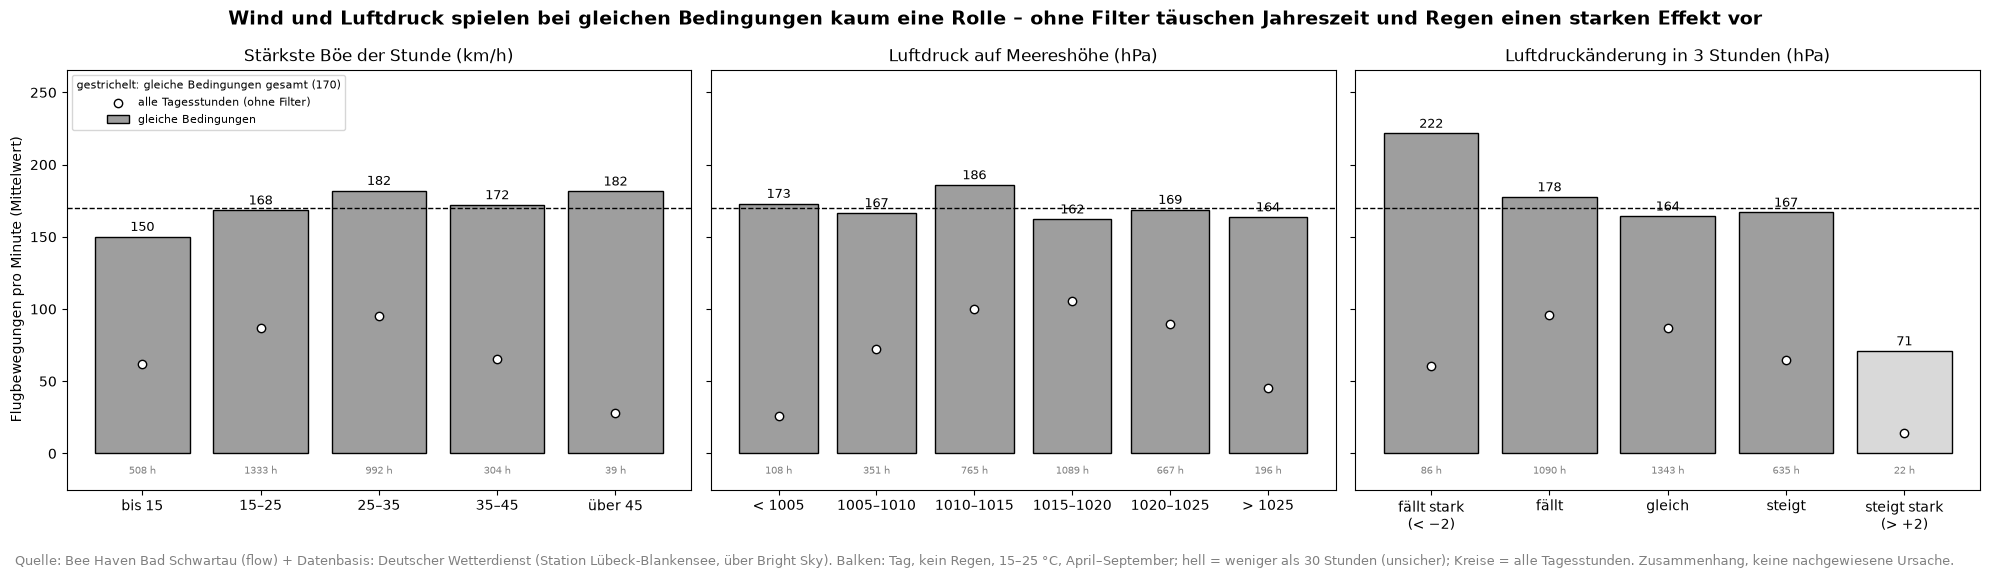

bewegungen  stunden  bewegungen_alle  \
windboeen_kmh    (0.0, 15.0]            150.0      508             62.0   
                 (15.0, 25.0]           168.0     1333             87.0   
                 (25.0, 35.0]           182.0      992             95.0   
                 (35.0, 45.0]           172.0      304             65.0   
                 (45.0, 100.0]          182.0       39             28.0   
luftdruck_hpa    (970.0, 1005.0]        173.0      108             26.0   
                 (1005.0, 1010.0]       167.0      351             72.0   
                 (1010.0, 1015.0]       186.0      765            100.0   
                 (1015.0, 1020.0]       162.0     1089            106.0   
                 (1020.0, 1025.0]       169.0      667             89.0   
                 (1025.0, 1050.0]       164.0      196             46.0   
druck_tendenz_3h (-20.0, -2.0]          222.0       86             61.0   
                 (-2.0, -0.5]           178.0     1090             96.0   
                 (-0.5, 0.5]            164.0     1343             87.0   
                 (0.5, 2.0]             167.0      635             65.0   
                 (2.0, 20.0]             71.0       22             14.0   

                                   stunden_alle  
windboeen_kmh    (0.0, 15.0]               2181  
                 (15.0, 25.0]              3833  
                 (25.0, 35.0]              2916  
                 (35.0, 45.0]              1250  
                 (45.0, 100.0]              447  
luftdruck_hpa    (970.0, 1005.0]           1337  
                 (1005.0, 1010.0]          1309  
                 (1010.0, 1015.0]          2120  
                 (1015.0, 1020.0]          2497  
                 (1020.0, 1025.0]          1841  
                 (1025.0, 1050.0]          1523  
druck_tendenz_3h (-20.0, -2.0]              654  
                 (-2.0, -0.5]              3130  
                 (-0.5, 0.5]               3742  
                 (0.5, 2.0]                2580  
                 (2.0, 20.0]                521

In [15]:
# --- A9/A10: Böen, Luftdruck (Höhe) und Luftdruckänderung (3 Std.) ---
fig, ax = plt.subplots(1, 3, figsize=(20, 5.5), sharey=True)
teile = [("windboeen_kmh", [0, 15, 25, 35, 45, 100], ["bis 15", "15–25", "25–35", "35–45", "über 45"], "Stärkste Böe der Stunde (km/h)"),
         ("luftdruck_hpa", [970, 1005, 1010, 1015, 1020, 1025, 1050], ["< 1005", "1005–1010", "1010–1015", "1015–1020", "1020–1025", "> 1025"], "Luftdruck auf Meereshöhe (hPa)"),
         ("druck_tendenz_3h", [-20, -2, -0.5, 0.5, 2, 20], ["fällt stark\n(< −2)", "fällt", "gleich", "steigt", "steigt stark\n(> +2)"], "Luftdruckänderung in 3 Stunden (hPa)")]
ergebnis_a9 = {}
for a, (spalte, grenzen, namen, titel) in zip(ax, teile):
    v = je_klasse(spalte, grenzen, vergleichbar)                                  # gleiche Bedingungen
    alle = je_klasse(spalte, grenzen, tag_std)                                    # alle Tagesstunden
    ergebnis_a9[spalte] = v.join(alle, rsuffix="_alle")
    x = range(len(v))
    farben = ["#9e9e9e" if n >= 30 else "#d9d9d9" for n in v["stunden"]]          # neutral grau (keine Wertung); hellgrau = weniger als 30 Stunden (unsicher)
    a.bar(x, v["bewegungen"], color=farben, edgecolor="black", label="gleiche Bedingungen")
    a.scatter(x, alle["bewegungen"].reindex(v.index), color="white", edgecolors="black", zorder=3, label="alle Tagesstunden (ohne Filter)")
    for xi, (m, n) in zip(x, v.to_numpy()):
        a.text(xi, m + 4, f"{m:.0f}", ha="center", fontsize=9)
        a.text(xi, -14, f"{n:.0f} h", ha="center", fontsize=7, color="grey")
    a.axhline(basis, color="black", ls="--", lw=1)
    a.set_xticks(list(x), [namen[grenzen.index(i.left) if i.left in grenzen else k] for k, i in enumerate(v.index)])
    a.set(title=titel, ylim=(-25, None))
ax[0].set_ylabel("Flugbewegungen pro Minute (Mittelwert)")
ax[0].set_ylim(-25, max(t["bewegungen"].max() for t in ergebnis_a9.values()) * 1.2)   # Platz für die Beschriftung
ax[0].legend(loc="upper left", fontsize=8, title=f"gestrichelt: gleiche Bedingungen gesamt ({basis:.0f})", title_fontsize=8)
fig.suptitle("Wind und Luftdruck spielen bei gleichen Bedingungen kaum eine Rolle – ohne Filter täuschen Jahreszeit und Regen einen starken Effekt vor",
             fontsize=14, fontweight="bold")
fig.text(0.01, -0.03, f"Quelle: Bee Haven {ORT['name']} (flow) + Datenbasis: Deutscher Wetterdienst (Station {STATION_T}, über Bright Sky). "
         "Balken: Tag, kein Regen, 15–25 °C, April–September; hell = weniger als 30 Stunden (unsicher); Kreise = alle Tagesstunden. Zusammenhang, keine nachgewiesene Ursache.", fontsize=9, color="grey")
plt.tight_layout()
plt.savefig(BILDER / "a9_a10_flug_wind_luftdruck.png", dpi=120, bbox_inches="tight")
plt.show()
pd.concat(ergebnis_a9).round(0)

**Ergebnis (A9/A10):** Grafik (`a9_a10_flug_wind_luftdruck.png`) und Tabelle: Balken = unter gleichen Bedingungen, Kreise/Punkte = alle Tagesstunden ohne Filter. Der Unterschied zeigt, wie stark Jahreszeit und Regen sonst täuschen (ohne Filter scheint starker Wind den Flug fast zu stoppen).

| Kernaussagen je Stadt | Böen · Luftdruck (Höhe) · Luftdruckänderung |
| :-- | :-- |
| Schwartau | kein Rückgang, selbst über 45 km/h (182; 39 h) · kein Einfluss (162–186) · stark fallender Druck mehr Flug (222; 86 h), stark steigender weniger (71; 22 h) |
| Würzburg | leichter Rückgang erst über 45 km/h (63 statt 76–90) · kein klarer Einfluss · siehe Ausgabe |

**Deutung (Hypothese, nicht belegt):** vor einem Wetterumschwung verstärkter Sammelflug, nach Durchzug einer Kaltfront Zurückhaltung. **Vergleich mit der Recherche:** Studien messen schon ab ca. 10 km/h Wind 37 % weniger Sammelleistung [R3] – am Flugloch sehen wir das nicht. Gründe: Messhöhe 10 m und Entfernung der Station, geschützter Standort, Zählung von Flugbewegungen statt Sammelrate.

## 6b. H1 – Honigproduktion: Wann nimmt der Stock zu?

**Idee:** Die Waage wird auf 2 Werte je Tag (00:00 und 12:00 UTC) vereinheitlicht (Schwartau misst so, Würzburg minütlich). Die Änderung **von Nacht zu Nacht** (alle Bienen im Stock) ist die Tagesbilanz: Nektar- und Polleneintrag minus Verbrauch und verdunstetes Wasser. Die beiden Hälften zeigen zusätzlich den Tagesgang: **00→12 UTC** (Vormittag, Sammlerinnen unterwegs) und **12→00 UTC** (Nachmittag + Nacht, Rückkehr und Eindicken).

**Einteilung der Tage (Saison April–August):** niedrig = Stock nimmt nicht zu (≤ 0 kg, Verbrauch überwiegt) · mittel = bis +0,5 kg · hoch = über +0,5 kg.

**Ausgeschlossen:** Zeiträume aus `ausschluesse.csv` (z. B. Schwartau E5) und Tagesänderungen über ±5 kg (Annahme: Eingriff der Imkerei, z. B. Ernte, Fütterung, Honigraum – mit Imkerei-Protokoll zu prüfen).

**Eigene Erwartung:** hohe Produktion an warmen, sonnigen, trockenen Tagen mit vielen Einflügen

**Erwartung laut Recherche:**
- Nektarlast je Flug ca. 30–50 mg [R6]; aus ca. 3 kg Nektar entsteht ca. 1 kg Honig [R2] → **ca. 10–17 mg Honig je Nektarflug** (nicht jeder Einflug bringt Nektar: auch Pollen, Wasser, Orientierungsflüge).
- Tageszunahme in der Tracht: mehrere Kilogramm [R2], an Spitzentagen 4–10 kg Nektar [R1].
- Tagesgang: morgens Abnahme (Sammlerinnen fliegen aus), ab Mittag Zunahme, abends und nachts Abnahme durch Verdunstung beim Eindicken [R2][R5].

In [16]:
# --- H1: Gewichtsänderung je Tag und je Tageshälfte (Gramm) ---
wg = gueltig["weight"][["zeit_utc", "weight"]].copy()                              # gültige Gewichtswerte (Gramm)
wg = wg.set_index("zeit_utc").sort_index()["weight"]
wg = wg.resample("12h").first().dropna()                                          # auf 00:00/12:00 UTC vereinheitlichen (Schwartau misst so, Würzburg minütlich)
diff12 = wg.diff()[wg.index.to_series().diff() == pd.Timedelta(hours=12)]          # Änderung je 12 Stunden (nur direkt aufeinanderfolgend)
nacht = wg[wg.index.hour == 0]                                                     # Messung 00:00 UTC (alle Bienen im Stock)
tagesbilanz = nacht.diff()[nacht.index.to_series().diff() == pd.Timedelta(days=1)]  # Nacht zu Nacht
tagesbilanz.index = (tagesbilanz.index - pd.Timedelta(days=1)).tz_convert(ZEITZONE).tz_localize(None).normalize()  # zugehöriger Kalendertag

h1 = pd.DataFrame({"bilanz_g": tagesbilanz})
h1["vormittag_g"] = diff12[diff12.index.hour == 12].set_axis(
    (diff12[diff12.index.hour == 12].index).tz_convert(ZEITZONE).tz_localize(None).normalize()).reindex(h1.index)   # 00→12 UTC
h1["nachmittag_nacht_g"] = h1["bilanz_g"] - h1["vormittag_g"]                      # 12→00 UTC (Rest der Tagesbilanz)
stoerung = np.zeros(len(h1), dtype=bool)                                           # bekannte Ausfallzeiträume (konfiguration/ausschluesse.csv)
for _, a in AUSSCHLUESSE[AUSSCHLUESSE["sensor"] == "weight"].iterrows():
    stoerung |= (h1.index >= a["von_utc"].tz_convert(ZEITZONE).tz_localize(None).normalize()) & (h1.index <= a["bis_utc"].tz_convert(ZEITZONE).tz_localize(None).normalize())
eingriff = h1["bilanz_g"].abs() > 5000                                             # Annahme: Eingriff der Imkerei
print("ausgeschlossen: Störzeiträume", int(stoerung.sum()), "Tage · vermutete Eingriffe:",
      {str(d.date()): f"{g / 1000:+.1f} kg" for d, g in h1.loc[eingriff, "bilanz_g"].items()})
h1 = h1[~stoerung & ~eingriff]

# --- Einflüge je Kalendertag (Ortszeit, nur Tage mit fast vollständigen flow-Daten) ---
ein_tag = fl.assign(tag_lokal=fl["zeit_utc"].dt.tz_convert(ZEITZONE).dt.tz_localize(None).dt.normalize(),
                    ein_ok=fl["flow_ein"].where(~fl["flow_ein_auffaellig"])) \
            .groupby("tag_lokal").agg(einfluege=("ein_ok", "sum"), minuten=("flow_ein", "size"))   # auffällige Werte (R9) nicht mitzählen
ein_tag = ein_tag[ein_tag["minuten"] >= 1300]["einfluege"]

# --- Tageswetter (nur Stunden bei Tageslicht) ---
wt = w_std.assign(tag_lokal=w_std["zeit_utc"].dt.tz_convert(ZEITZONE).dt.tz_localize(None).dt.normalize(),
                  abstand_taupunkt_c=w_std["aussentemperatur_c"] - w_std["taupunkt_c"])
hell_w = wt[wt["tageszeit"] == "Tag"].groupby("tag_lokal")
tageswetter = pd.DataFrame({
    "temperatur_c": hell_w["aussentemperatur_c"].mean(),                           # Mittel bei Tageslicht
    "sonne_h": wt.groupby("tag_lokal")["sonnenschein_min"].sum() / 60,             # Sonnenstunden
    "strahlung_kwh_m2": wt.groupby("tag_lokal")["sonnenstrahlung_kwh_m2"].sum(),   # Tagessumme Strahlung
    "regen_mm": wt.groupby("tag_lokal")["niederschlag_mm"].sum(),                  # Tagessumme Niederschlag
    "boee_max_kmh": hell_w["windboeen_kmh"].max(),                                 # stärkste Böe bei Tageslicht
    "luftdruck_hpa": hell_w["luftdruck_hpa"].mean(),
    "abstand_taupunkt_c": hell_w["abstand_taupunkt_c"].mean(),                     # Feuchte (klein = feucht)
})
h1 = h1.join(ein_tag, how="inner").join(tageswetter, how="left")
h1 = h1[h1.index.month.isin([4, 5, 6, 7, 8])]                                      # Saison April–August
h1["produktion"] = pd.cut(h1["bilanz_g"], [-np.inf, 0, 500, np.inf], labels=["niedrig (≤ 0 kg)", "mittel (bis +0,5 kg)", "hoch (> +0,5 kg)"])
print(f"{len(h1)} Saisontage auswertbar")
h1.groupby("produktion", observed=True).agg(tage=("bilanz_g", "size"), median_kg=("bilanz_g", lambda v: v.median() / 1000)) \
  .assign(anteil_pct=lambda t: t["tage"] / t["tage"].sum() * 100).round(2)

ausgeschlossen: Störzeiträume 0 Tage · vermutete Eingriffe: {'2017-04-20': '+6.2 kg', '2017-06-06': '-9.2 kg', '2017-07-26': '-31.9 kg', '2017-08-06': '+7.7 kg', '2017-09-06': '+6.4 kg', '2017-11-06': '-6.1 kg'}
290 Saisontage auswertbar


,tage,median_kg,anteil_pct
produktion,,,
niedrig (≤ 0 kg),156,-0.19,53.79
"mittel (bis +0,5 kg)",78,0.15,26.90
"hoch (> +0,5 kg)",56,1.09,19.31


**Ergebnis (H1, Einteilung):** Die Ausgabe nennt ausgeschlossene Tage (Störzeiträume, vermutete Eingriffe über ±5 kg), die auswertbaren Saisontage und je Klasse Anzahl, Median und Anteil.

| Kernaussagen je Stadt | Saisontage · niedrig / mittel / hoch (Anteil, Median) |
| :-- | :-- |
| Schwartau | 290 · 54 % (−0,19 kg) / 27 % (+0,15 kg) / 19 % (+1,09 kg); ausgeschlossen 12 Tage E5 und 6 Eingriffe, u. a. −31,9 kg am 26.07.2017 (vermutlich Honigernte) |
| Würzburg | 249 · 58 % (−0,16 kg) / 26 % (+0,16 kg) / 16 % (+0,86 kg); 3 vermutete Eingriffe (+5,3 bis +13,2 kg, z. B. Fütterung) |

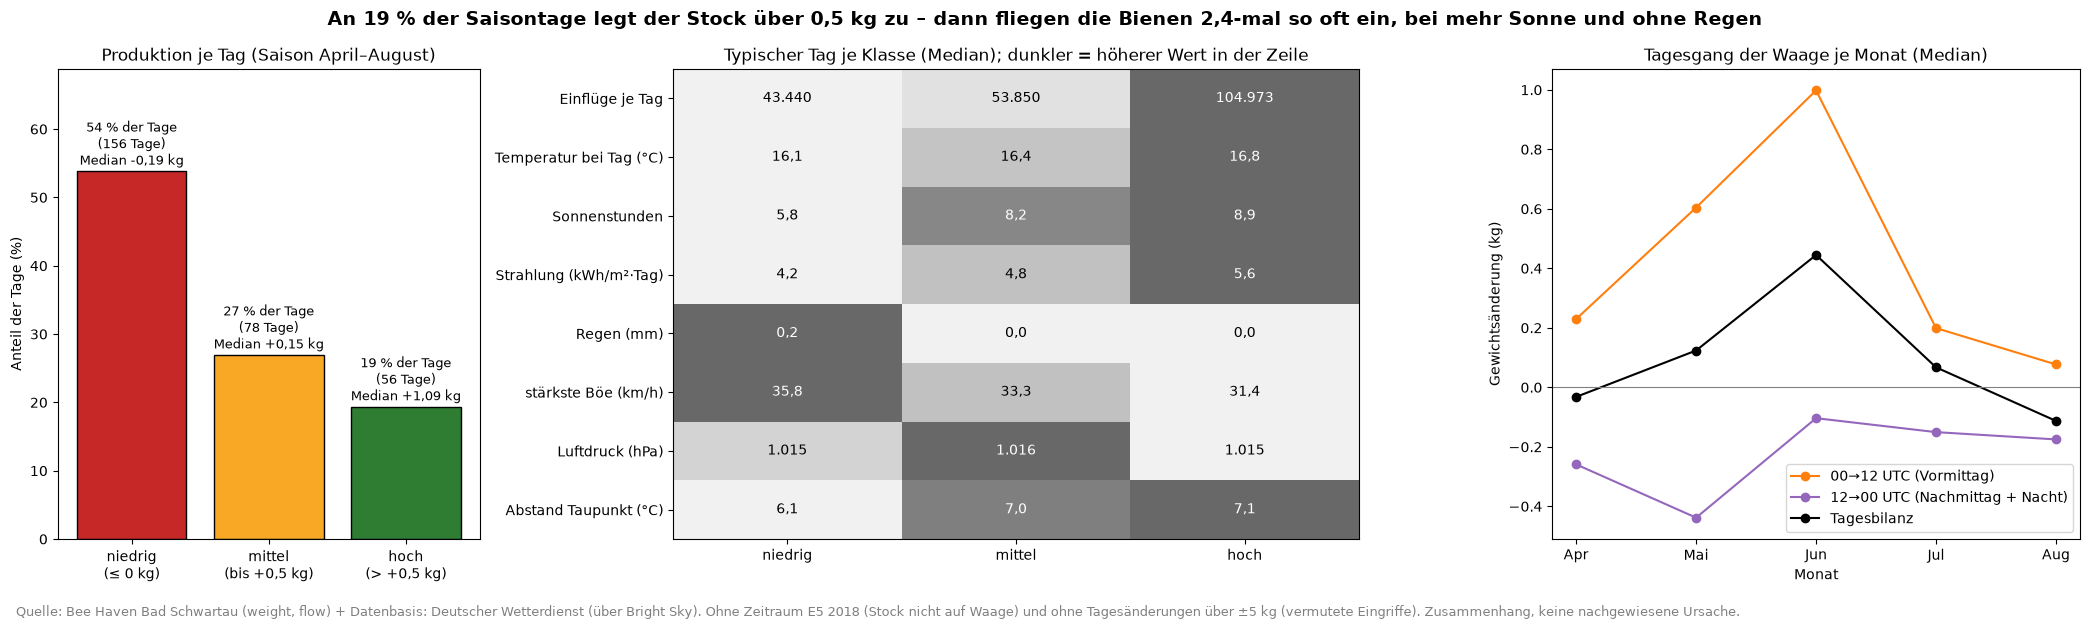

Gerade: 6.3 mg je Einflug · Verbrauch bei 0 Einflügen: -259 g/Tag · Gewinnschwelle bei ca. 41.456 Einflügen/Tag · r = 0.45


produktion,niedrig (≤ 0 kg),"mittel (bis +0,5 kg)","hoch (> +0,5 kg)"
einfluege,43439.5,53850.0,104973.0
temperatur_c,16.1,16.4,16.8
sonne_h,5.8,8.2,8.9
strahlung_kwh_m2,4.2,4.8,5.6
regen_mm,0.2,0.0,0.0
boee_max_kmh,35.8,33.3,31.4
luftdruck_hpa,1015.1,1016.3,1014.7
abstand_taupunkt_c,6.1,7.0,7.1


In [17]:
# --- H1 Grafik: Anteil der Tage, Bedingungen je Produktionsklasse, Tagesgang der Waage ---
klassen = h1.groupby("produktion", observed=True)
bedingungen = klassen[["einfluege", "temperatur_c", "sonne_h", "strahlung_kwh_m2", "regen_mm", "boee_max_kmh", "luftdruck_hpa", "abstand_taupunkt_c"]].median()
namen_b = {"einfluege": "Einflüge je Tag", "temperatur_c": "Temperatur bei Tag (°C)", "sonne_h": "Sonnenstunden",
           "strahlung_kwh_m2": "Strahlung (kWh/m²·Tag)", "regen_mm": "Regen (mm)", "boee_max_kmh": "stärkste Böe (km/h)",
           "luftdruck_hpa": "Luftdruck (hPa)", "abstand_taupunkt_c": "Abstand Taupunkt (°C)"}
steigung, achse = np.polyfit(h1["einfluege"], h1["bilanz_g"], 1)                   # Gerade: Gramm je Einflug + Verbrauch bei 0 Flug

fig, ax = plt.subplots(1, 3, figsize=(21, 6), gridspec_kw={"width_ratios": [0.8, 1.3, 1]})
anteil = klassen.size() / len(h1) * 100
median_kg = klassen["bilanz_g"].median() / 1000
b = ax[0].bar(range(3), anteil, color=["#c62828", "#f9a825", "#2e7d32"], edgecolor="black")   # Ampel (Farbregel): niedrig = rot, mittel = gelb, hoch = grün
for i, (p, m, n) in enumerate(zip(anteil, median_kg, klassen.size())):
    ax[0].text(i, p + 1, f"{p:.0f} % der Tage\n({n} Tage)\nMedian {m:+.2f} kg".replace(".", ","), ha="center", fontsize=9)
ax[0].set_xticks(range(3), [str(k).replace(" (", "\n(") for k in anteil.index])
ax[0].set(title="Produktion je Tag (Saison April–August)", ylabel="Anteil der Tage (%)", ylim=(0, anteil.max() + 15))

norm = (bedingungen - bedingungen.min()) / (bedingungen.max() - bedingungen.min())  # je Zeile 0–1 für die Farbe
ax[1].imshow(norm.T, cmap="Greys", aspect="auto", vmin=-0.2, vmax=1.6)   # neutral grau (Farbregel): dunkler = höherer Wert, keine Wertung
for (i, j), v in np.ndenumerate(bedingungen.T.to_numpy()):
    ax[1].text(j, i, f"{v:,.0f}".replace(",", ".") if abs(v) >= 100 else f"{v:.1f}".replace(".", ","), ha="center", va="center", fontsize=10,
                color="white" if norm.T.to_numpy()[i, j] > 0.7 else "black")   # auf dunklem Grau weiße Schrift
ax[1].set_xticks(range(3), [str(k).split(" (")[0] for k in bedingungen.index])
ax[1].set_yticks(range(len(namen_b)), [namen_b[c] for c in bedingungen.columns])
ax[1].set_title("Typischer Tag je Klasse (Median); dunkler = höherer Wert in der Zeile")

monat = h1.index.month
gang = pd.DataFrame({"00→12 UTC (Vormittag)": h1.groupby(monat)["vormittag_g"].median(),
                     "12→00 UTC (Nachmittag + Nacht)": h1.groupby(monat)["nachmittag_nacht_g"].median(),
                     "Tagesbilanz": h1.groupby(monat)["bilanz_g"].median()}) / 1000
gang.plot(ax=ax[2], marker="o", color=["tab:orange", "tab:purple", "black"])
ax[2].axhline(0, color="grey", lw=0.8)
ax[2].set_xticks(gang.index, [monatsnamen[m - 1] for m in gang.index])
ax[2].set(title="Tagesgang der Waage je Monat (Median)", xlabel="Monat", ylabel="Gewichtsänderung (kg)")
fig.suptitle("An 19 % der Saisontage legt der Stock über 0,5 kg zu – dann fliegen die Bienen 2,4-mal so oft ein, bei mehr Sonne und ohne Regen",
             fontsize=14, fontweight="bold")
fig.text(0.01, -0.03, f"Quelle: Bee Haven {ORT['name']} (weight, flow) + Datenbasis: Deutscher Wetterdienst (über Bright Sky). Ohne Zeitraum E5 2018 (Stock nicht auf Waage) "
         "und ohne Tagesänderungen über ±5 kg (vermutete Eingriffe). Zusammenhang, keine nachgewiesene Ursache.", fontsize=9, color="grey")
plt.tight_layout()
plt.savefig(BILDER / "h1_honig_produktion.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"Gerade: {steigung * 1000:.1f} mg je Einflug · Verbrauch bei 0 Einflügen: {achse:.0f} g/Tag · "
      f"Gewinnschwelle bei ca. {-achse / steigung:,.0f} Einflügen/Tag · r = {h1['einfluege'].corr(h1['bilanz_g']):.2f}".replace(",", "."))
bedingungen.T.round(1)

**Ergebnis (H1, Bedingungen und Tagesgang):** Die Ausgabe nennt die Ausgleichsgerade (Zunahme je Einflug, Verbrauch ohne Flug, Gewinnschwelle, r) und je Klasse die typischen Bedingungen (Einflüge, Temperatur, Sonne, Strahlung, Regen, Böen, Luftdruck, Feuchte).

| Kernaussagen je Stadt | Gramm je Einflug · Verbrauch ohne Flug · Gewinnschwelle · Tag mit hoher Produktion |
| :-- | :-- |
| Schwartau | ca. 6 mg · ca. 260 g/Tag · ca. 41.000 Einflüge/Tag (r = 0,45) · ca. 105.000 Einflüge (niedrig 43.000), 8,9 Sonnenstunden (niedrig 5,8), kein Regen; Temperatur unterscheidet die Klassen kaum (16,1 / 16,4 / 16,8 °C) |
| Würzburg | ca. 7,8 mg · ca. 156 g/Tag · ca. 20.000 Einflüge/Tag (r = 0,32) · ca. 51.500 Einflüge (niedrig 19.800), 10,8 Sonnenstunden (niedrig 5,8), 19 °C statt 16 °C |

**Einordnung:** Recherche 10–17 mg Honig je **Nektar**flug → wenige Milligramm je Einflug sind plausibel, weil ein Teil der Einflüge Pollen, Wasser oder Orientierungsflüge sind und das Volk gleichzeitig verbraucht. Innerhalb der Saison entscheiden Sonne, Regen und Tracht mehr als die Temperatur. Würzburg braucht weniger Einflüge für einen Gewinn (kleineres Volk, geringerer Verbrauch).

**Tagesgang (Schwartau):** 00→12 UTC nimmt der Stock in allen Monaten zu (Juni Median +1,0 kg), 12→00 UTC ab (−0,1 bis −0,4 kg) – die nächtliche Abnahme durch Verdunstung [R2][R5] wird bestätigt; die morgendliche Abnahme ist mit nur 2 Messungen am Tag nicht sichtbar. Tageszunahmen von 4–10 kg [R1] kommen nur als vermutete Eingriffe vor.

### Quellen zu den Erwartungen (Recherche 29.09.2026)

- [R1] Wikipedia, „Honey flow“ (Tageszunahme 4–10 kg an Spitzentagen): https://en.wikipedia.org/wiki/Honey_flow
- [R2] BEEP Bijenmonitoring, „Weight – data interpretation“ (Tagesgang, Verdunstung nachts, Winterverbrauch, ca. 3 kg Nektar → 1 kg Honig): https://beep.nl/measurement-system-2/data-interpretation/weight
- [R3] Übersichtsarbeit „A review of short-term weather impacts on honey production“, International Journal of Biometeorology (2025): https://pmc.ncbi.nlm.nih.gov/articles/PMC11785677/
- [R4] „Predictive modelling of honey bee foraging activity using local weather conditions“, Apidologie (2018): https://link.springer.com/content/pdf/10.1007/s13592-018-0565-3.pdf
- [R5] „Using within-day hive weight changes to measure environmental effects on honey bee colonies“, PLOS ONE (2018): https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0197589
- [R6] „Dietary requirements of individual nectar foragers …“, Apidologie (2019), sowie Nektarlast 30–50 mg laut ScienceDirect-Themenübersicht „Nectar Foraging“: https://link.springer.com/article/10.1007/s13592-019-00694-9

Hinweis: Die Studien beobachten andere Standorte, Völker und Messmethoden (z. B. Sammelrate an Blüten statt Zählung am Flugloch) – Abweichungen zu den eigenen Ergebnissen sind daher zu erwarten und werden im Ergebnis benannt.

## Zusammenfassung N5

| Frage | Schwartau | Würzburg | Grafik (`04_images/<stadt>/`) |
| :-- | :-- | :-- | :-- |
| F1 Gewicht | Median ca. 60 kg, Höchstwert 91 kg; vermutete Honigernte −32 kg (Juli 2017); Winterverbrauch 7–12 kg | Median 53,7 kg, Höchstwert 68,5 kg; keine deutliche Ernte | `f1_gewicht_verlauf.png` |
| F2 Flugsaison | Mai–August, Höhepunkt Juni | April–August, Höhepunkt Juni | `f2_flugaktivitaet_monat.png` |
| F3 Temperatur | r = 0,68 (außen) | r = 0,70 (außen) | `f3_temperatur_einflug.png` |
| A2 Tageszeit | 90 % Tag, 3 % Dämmerung, 7 % Nacht | Sommer 83–92 % Tag | `a2_flug_tageszeit.png` |
| A3/A5 Außentemperatur | Flug ab 5 °C, Maximum 20–30 °C; Hitze-Effekt nicht belegt | steigt bis über 30 °C (wenige Stunden) | `a3_a5_flug_temperatur.png` |
| A4/A6 Regen, Sonne | Regen −58 %, volle Sonne ca. 3 × | Regen −69 %, volle Sonne ca. 5 × | `a4_a6_flug_regen_sonne_stunde.png` |
| A7 Feuchte | am Tag: je trockener, desto mehr Flug | ebenso | `a7_flug_feuchte.png` |
| A8 Strahlung × Hitze | Strahlung steigert den Flug; über 30 °C −33 % (wenige Stunden) | Strahlung steigert den Flug; kein Hitze-Rückgang | `a8_flug_strahlung_hitze.png` |
| A9/A10 Wind, Luftdruck | kein Einfluss unter gleichen Bedingungen | leichter Rückgang erst über 45 km/h | `a9_a10_flug_wind_luftdruck.png` |
| H1 Honig | 6 mg je Einflug, Gewinnschwelle ca. 41.000 Einflüge/Tag, 19 % Tage mit hoher Produktion | 7,8 mg, ca. 20.000 Einflüge/Tag, 16 % | `h1_honig_produktion.png` |

**Weiter in Folgeprojekten (Projektplan PP-ITS-002 Kap. 8):** Einzelwirkung der Faktoren trennen (FP-3 Machine Learning; A7/A8/H1 zeigen, wie stark sich Sonne, Feuchte und Jahreszeit überlagern) · Imkerei-Protokoll (Ernte, Fütterung, Honigräume) und fachliche Belege zum Flugverhalten (FP-2, mit einer Imkerei). Geklärt: Vorzeichen flow (positiv = Einflug) und Befund E5 (Ausfallzeitraum in `ausschluesse.csv`).